---

## 1. Planteamiento del Problema y Comprensión de los Datos

<details open>
  <summary><b>1.1 Planteamiento del Problema y Objetivos de Investigación</b></summary>

**Planteamiento del Problema:**

En una operación minorista que utiliza incentivos comerciales como descuentos promocionales de hasta el 20 % y envío gratuito a partir de \$75.00 USD, un incremento en las ventas brutas no necesariamente representa una mejora en la rentabilidad del negocio.

La aplicación simultánea de descuentos, promociones de envío gratuito y políticas de devolución puede reducir los ingresos que finalmente conserva la empresa. Por ello, analizar únicamente el volumen de ventas o los ingresos registrados puede ofrecer una visión incompleta del desempeño financiero de la operación.

En este contexto, el problema central de este estudio consiste en **analizar cómo las políticas de incentivos comerciales, el estado de los cobros y las devoluciones se relacionan con la utilidad bruta del negocio**, considerando distintos niveles de análisis: orden de compra, categoría y producto (SKU).

**Objetivo de Investigación:**

Realizar un Análisis Exploratorio de Datos que permita evaluar el desempeño comercial y la rentabilidad de la operación, delimitando el estudio a dos ejes principales:

1. **Eje 1 — Descuentos y Envío Gratuito:** Identificar cómo se comporta la utilidad por orden de compra ante distintos niveles de descuento y la aplicación de la política de envío gratuito (subtotal igual o superior a \$75.00 USD), con el propósito de reconocer los segmentos de compra en los que estas condiciones se asocian con una menor rentabilidad.

2. **Eje 2 — Concentración de Utilidad y Devoluciones por Producto:** Determinar qué proporción del catálogo activo concentra el 80 % de la utilidad bruta y analizar qué parte de estos productos presenta tasas de devolución superiores al promedio de su respectiva categoría.

</details>

<details>
  <summary><b>1.2 Descripción General, Procedencia y Contexto de Generación</b></summary>

El conjunto de datos utilizado representa la operación comercial, transaccional y financiera de una empresa minorista especializada en equipamiento para actividades al aire libre. La información comprende un periodo de **33 meses**, del **1 de enero de 2024 al 29 de septiembre de 2026**, e incluye cuatro canales de venta: tienda web (`web`), aplicación móvil (`app`), `marketplace` y tienda física (`store`).

* **Procedencia:** El conjunto de datos corresponde a una base de datos relacional sintética, generada mediante el motor *GenerateRealData* a partir de un esquema SQL y un conjunto de reglas comerciales predefinidas. Su estructura permite representar las relaciones entre las distintas tablas y realizar verificaciones de consistencia durante el análisis.

* **Contexto Operativo y Reglas de Negocio:** La información fue generada considerando las siguientes condiciones de operación:

  * **Estructura de costos:** El costo de adquisición de los productos (`unit_cost`) representa entre el **35 % y el 70 %** de su precio de venta (`unit_price`).
  * **Política de descuentos:** Se aplican descuentos promocionales de hasta el **20 %** sobre el subtotal de la orden (`discount_amount`).
  * **Umbral de envío gratuito:** Las compras con un subtotal igual o superior a **\$75.00 USD** cuentan con envío gratuito (`shipping_fee = 0`). Para compras inferiores a este monto se registra una tarifa de envío de entre **\$4.99 y \$9.99 USD**.
  * **Comportamiento de la demanda y postventa:** Los registros contemplan variaciones estacionales en las ventas, con mayor actividad durante noviembre y diciembre, así como distintos estados de pago, cancelaciones y devoluciones. Estas últimas pueden generar reembolsos totales o parciales.

</details>

<details open>
  <summary><b>1.3 Estructura de la Base de Datos, Unidades de Observación y Variables Disponibles</b></summary>

**Selección de Tablas:**

De las siete tablas que conforman la base de datos original, se seleccionaron las **cinco tablas principales** para el análisis, ya que contienen la información necesaria sobre ventas, productos, costos, pagos y devoluciones.

| Tabla | Registros | Función en el análisis | Justificación de selección |
| :--- | :---: | :--- | :--- |
| **`orders`** | 90,000 | Información general de las órdenes | Contiene la fecha, el canal de venta, el estado del pedido y los importes registrados a nivel de orden (`subtotal`, `discount_amount`, `shipping_fee`, `tax_amount`, `total_amount`). |
| **`order_items`** | 200,000 | Detalle de los productos vendidos | Desglosa cada orden en sus artículos individuales (`quantity`, `unit_price`, `line_total`), lo que permite relacionar las ventas con los costos de los productos. |
| **`products`** | 1,500 | Información del catálogo y costos | Proporciona información sobre los productos, como categoría, marca y SKU, además de su costo unitario (`unit_cost`), necesario para estimar la utilidad bruta. |
| **`payments`** | 90,000 | Registro de pagos | Permite identificar el estado de los pagos (`captured`, `refunded`, `failed`), los métodos utilizados (`method`) y los importes registrados, para evaluar el cobro de las órdenes. |
| **`returns`** | 8,000 | Registro de devoluciones | Contiene información sobre los productos devueltos, los motivos de devolución (`reason`), las fechas correspondientes y los importes reembolsados (`refund_amount`). |

**Exclusiones justificadas:**

Se excluyeron las tablas `customers` y `shipments`.

- **`customers`:** No se incorpora debido a que el estudio se concentra en la rentabilidad de los productos y el comportamiento de los incentivos comerciales, sin abordar la segmentación de clientes por características demográficas.
- **`shipments`:** Se excluye porque el análisis se enfoca en las condiciones comerciales y financieras asociadas al envío, y no en los tiempos o el desempeño operativo de las entregas.

**Unidades de Observación:**

Debido a la estructura relacional de la base de datos, se utilizan dos unidades de observación, de acuerdo con el objetivo de cada eje de análisis:

1. **Orden de compra (`order_id`):** Se utiliza como unidad de análisis para evaluar la relación entre los descuentos, la política de envío gratuito y el estado de los pagos a nivel de transacción (Correspondiente al eje 1).

2. **Línea de producto dentro de una orden (`order_item_id`):** Se utiliza para analizar la utilidad generada por cada producto y el comportamiento de las devoluciones a nivel de SKU (Correspondiente al eje 2).

**Variables Disponibles por Dimensión:**

Las variables seleccionadas para el análisis se agrupan de acuerdo con la información que proporcionan:

* **Identificación y relaciones entre tablas:** `order_id`, `order_item_id`, `product_id`, `payment_id`, `sku`.
* **Operativas y temporales:** `order_date`, `paid_at`, `created_at`, `requested_at`, canal de venta (`channel`) y estado de la orden (`orders.status`).
* **Catálogo y costos:** `product_name`, `category`, `brand`, `unit_price`, `unit_cost`, `weight_kg` e `is_active`.
* **Financieras y transaccionales:** `quantity`, `line_total`, `subtotal`, `discount_amount`, `shipping_fee`, `tax_amount`, `total_amount`, `currency`, método de pago (`method`), importe del pago (`amount`) y estado del pago (`payments.status`).
* **Devoluciones y postventa:** `return_id`, `reason`, estado de la devolución (`returns.status`) e importe reembolsado (`refund_amount`).

</details>

---
## Carga de datos

En esta sección se realiza la carga de las tablas que conforman la base de datos del proyecto. Se establecen las rutas de acceso a los archivos, se importan las librerías necesarias y se almacenan los datos en estructuras que permitan su posterior consulta y análisis.

El objetivo es disponer de la información necesaria para realizar una primera revisión de su contenido y estructura.

In [211]:
import numpy as np
import pandas as pd
from pathlib import Path
import sys
from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import matplotlib.ticker as mtick
from scipy.stats import chi2_contingency, mannwhitneyu, kruskal, kstest

### 1.4.1 Configuración de archivos y funciones de carga

Se definen los nombres de los archivos CSV, las columnas requeridas y las variables que deben interpretarse como fechas. Asimismo, se establecen funciones auxiliares para localizar los archivos, importar las tablas y generar un resumen de sus características generales.

Esta configuración permite centralizar el proceso de lectura y facilitar su reutilización durante el análisis.

In [212]:
from pathlib import Path

BASE_DIR = Path.cwd().parent

# Carpeta para guardar resultados
RESULTS_DIR = BASE_DIR / "results"

# Crear carpeta si no existe
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(RESULTS_DIR)

c:\Users\aleca\OneDrive\Documentos\POYECTOFINAL\results


In [213]:
FILE_NAMES = {
    "orders": "orders.csv",
    "items": "order_items.csv",
    "products": "products.csv",
    "returns": "returns.csv",
    "payments": "payments.csv",
}

REQUIRED = list(FILE_NAMES.keys())

EXPECTED = {
    "orders": [
        "order_id", "customer_id", "order_date", "status", "channel",
        "subtotal", "discount_amount", "shipping_fee", "tax_amount",
        "total_amount", "currency"
    ],
    "items": [
        "order_item_id", "order_id", "product_id", "quantity",
        "unit_price", "line_total"
    ],
    "products": [
        "product_id", "sku", "product_name", "category", "brand",
        "unit_price", "unit_cost", "weight_kg", "is_active", "created_at"
    ],
    "returns": [
        "return_id", "order_item_id", "reason", "refund_amount",
        "requested_at", "status"
    ],
    "payments": [
        "payment_id", "order_id", "method", "amount", "paid_at", "status"
    ],
}

DATE_COLS = {
    "orders": ["order_date"],
    "products": ["created_at"],
    "returns": ["requested_at"],
    "payments": ["paid_at"],
}


def table_inventory(tables: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Resumen de filas, columnas, nulos, duplicados y memoria."""
    return pd.DataFrame([{
        "tabla": name,
        "filas": len(df),
        "columnas": df.shape[1],
        "nulos": int(df.isna().sum().sum()),
        "duplicados": int(df.duplicated().sum()),
        "memoria_MiB": round(df.memory_usage(deep=True).sum() / 2**20, 2)
    } for name, df in tables.items()]).sort_values("tabla", ignore_index=True)


def detect_source(root: Path) -> tuple[Path, str]:
    """Localiza los cinco CSV en data/raw/ o root."""
    root = Path(root).resolve()
    candidatos = [root / "data" / "raw", root]
    for folder in candidatos:
        if folder.is_dir() and all((folder / name).is_file() for name in FILE_NAMES.values()):
            return folder, f"CSV raw: {folder}"
    missing = [name for name in FILE_NAMES.values() if not (root / "data" / "raw" / name).is_file()]
    raise FileNotFoundError(
        "Faltan CSV en data/raw/: " + ", ".join(missing)
    )


def read_tables(root: Path | None = None) -> tuple[dict[str, pd.DataFrame], str]:
    root = find_root() if root is None else Path(root)
    directory, source = detect_source(root)
    result = {}
    for key in REQUIRED:
        fn = directory / FILE_NAMES[key]
        col_list = pd.read_csv(fn, nrows=0).columns.tolist()
        force_str = {
            c: "string" for c in col_list
            if c.endswith("_id") or c in ["sku"]
        }
        tab = pd.read_csv(fn, dtype=force_str, encoding="utf-8-sig", low_memory=False)
        missing = set(EXPECTED[key]) - set(tab.columns)
        if missing:
            raise ValueError(
                f"{fn.name} no coincide con el esquema esperado; faltan columnas: {sorted(missing)}"
            )
        for c in DATE_COLS.get(key, []):
            if c in tab:
                if key == "payments" and c == "paid_at" and pd.api.types.is_numeric_dtype(tab[c]):
                    # Ajusta unit='s' o unit='ms' según la escala real de paid_at
                    tab[c] = pd.to_datetime(tab[c], unit="s", errors="coerce")
                else:
                    tab[c] = pd.to_datetime(tab[c], errors="coerce")
        result[key] = tab
    return result, source

### 1.4.2 Localización y carga de los archivos

Se identifica el directorio raíz del proyecto a partir de la ubicación actual del notebook y se localizan los archivos CSV esperados. Posteriormente, se cargan las cinco tablas y se presenta un inventario inicial que permite verificar su disponibilidad, dimensiones, valores faltantes, registros duplicados y uso de memoria.

In [214]:
ARCHIVOS_ESPERADOS = ["orders.csv", "order_items.csv", "products.csv", "returns.csv","payments.csv"]

ROOT = next(
    (p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (p / "data" / "raw").is_dir()
     or all((p / fn).is_file() for fn in ARCHIVOS_ESPERADOS)),
    Path.cwd().resolve()
)

TABLAS, ORIGEN = read_tables(ROOT)

In [215]:
print("ORIGEN:", ORIGEN)
print("Directorio raíz:", ROOT)
display(table_inventory(TABLAS))

ORIGEN: CSV raw: C:\Users\aleca\OneDrive\Documentos\POYECTOFINAL\data\raw
Directorio raíz: C:\Users\aleca\OneDrive\Documentos\POYECTOFINAL


,tabla,filas,columnas,nulos,duplicados,memoria_MiB
0,items,200000,6,0,0,11.74
1,orders,90000,11,0,0,9.75
2,payments,90000,6,0,0,6.15
3,products,1500,10,78,0,0.20
4,returns,8000,6,0,0,0.59


---

## 2. Exploración y estadística descriptiva

<details>
  <summary><b>Enfoque metodológico del diagnóstico descriptivo</b></summary>

Antes de ejecutar procesos de depuración, imputación o filtrado de registros, se realiza una exploración estadística de las cinco tablas disponibles (`orders`, `items`, `products`, `returns` y `payments`). El diagnóstico busca comprender la estructura, distribución y características generales de los datos, y se organiza en cuatro bloques:

1. **Medidas de tendencia central, dispersión y posición:** Evaluación de media, mediana, desviación estándar, rango intercuartílico, percentiles extremos (P05, P95, P99.5) y coeficiente de asimetría en variables numéricas relevantes.

2. **Distribución de frecuencias y dimensiones categóricas:** Análisis de la distribución de órdenes por canal de venta (`channel`), estatus (`status`), categoría de producto (`category`), motivos de devolución (`reason`) y características de los pagos (`method`, `status`).

3. **Comparación entre segmentos operativos:** Contraste de métricas monetarias y de volumen entre canales de venta y categorías de producto para identificar diferencias en su comportamiento.

4. **Análisis de correlación:** Evaluación de las asociaciones lineales mediante Pearson y de las asociaciones monotónicas mediante Spearman entre variables financieras de las órdenes.

La profundidad del análisis de cada tabla dependerá de su relevancia para los dos ejes de investigación: la relación entre descuentos, envío gratuito y rentabilidad por orden; y la concentración de utilidad y el comportamiento de las devoluciones por producto.

</details>

### 2.1 Auditoría de tipos de datos

Se define un contrato de tipos esperados para las columnas de cada tabla y se compara con los tipos detectados durante la lectura. La auditoría permite identificar columnas con tipos inconsistentes entre registros o cuyo tipo no corresponde con el establecido.

Al finalizar, se aplican aserciones de control para detener la ejecución si se detectan incumplimientos.

In [216]:
# Contrato de tipos esperados por columna
TIPOS_ESPERADOS = {
    "orders": {
        "order_id": "texto", "customer_id": "texto", "order_date": "fecha",
        "status": "texto", "channel": "texto", "subtotal": "numerica",
        "discount_amount": "numerica", "shipping_fee": "numerica",
        "tax_amount": "numerica", "total_amount": "numerica", "currency": "texto"
    },
    "items": {
        "order_item_id": "texto", "order_id": "texto", "product_id": "texto",
        "quantity": "numerica", "unit_price": "numerica", "line_total": "numerica"
    },
    "products": {
        "product_id": "texto", "sku": "texto", "product_name": "texto",
        "category": "texto", "brand": "texto", "unit_price": "numerica",
        "unit_cost": "numerica", "weight_kg": "numerica",
        "is_active": "numerica", "created_at": "fecha"
    },
    "returns": {
        "return_id": "texto", "order_item_id": "texto", "reason": "texto",
        "refund_amount": "numerica", "requested_at": "fecha", "status": "texto"
    },
    "payments": {
        "payment_id": "texto", "order_id": "texto", "method": "texto",
        "amount": "numerica", "paid_at": "fecha", "status": "texto"
    }

}

def auditar_tipos_fila_a_fila(tablas_dict, contrato):
    filas = []
    for tabla, df in tablas_dict.items():
        for col in df.columns:
            s_valid = df[col].dropna()
            tipos_celdas = s_valid.map(lambda x: type(x).__name__).value_counts().to_dict()

            if pd.api.types.is_numeric_dtype(df[col]):
                grupo_actual = "numerica"
            elif pd.api.types.is_datetime64_any_dtype(df[col]):
                grupo_actual = "fecha"
            else:
                grupo_actual = "texto"

            esperado = contrato.get(tabla, {}).get(col, "no_definido")
            es_homogeneo = (len(tipos_celdas) <= 1)
            cumple_contrato = (grupo_actual == esperado)

            filas.append({
                "tabla": tabla,
                "columna": col,
                "dtype_pandas": str(df[col].dtype),
                "grupo_detectado": grupo_actual,
                "grupo_esperado": esperado,
                "tipos_en_filas": str(tipos_celdas),
                "homogeneo_100pct": es_homogeneo,
                "cumple_contrato": cumple_contrato,
                "ejemplo": s_valid.iloc[0] if len(s_valid) > 0 else None
            })
    return pd.DataFrame(filas)

df_auditoria_tipos = auditar_tipos_fila_a_fila(TABLAS, TIPOS_ESPERADOS)
display(df_auditoria_tipos)

# Aserción de control: detiene el flujo si alguna fila tiene tipo mixto o incorrecto
assert df_auditoria_tipos["homogeneo_100pct"].all(), "Hay columnas con tipos mezclados entre filas."
assert df_auditoria_tipos["cumple_contrato"].all(), "Hay columnas cuyo dtype no coincide con el esperado."


,tabla,columna,dtype_pandas,grupo_detectado,grupo_esperado,tipos_en_filas,homogeneo_100pct,cumple_contrato,ejemplo
0,orders,order_id,string,texto,texto,{'str': 90000},True,True,1
1,orders,customer_id,string,texto,texto,{'str': 90000},True,True,1
2,orders,order_date,datetime64[us],fecha,fecha,{'Timestamp': 90000},True,True,2026-04-18 22:37:25
3,orders,status,str,texto,texto,{'str': 90000},True,True,delivered
4,orders,channel,str,texto,texto,{'str': 90000},True,True,app
5,orders,subtotal,float64,numerica,numerica,{'float': 90000},True,True,14.29
6,orders,discount_amount,float64,numerica,numerica,{'float': 90000},True,True,0.0
7,orders,shipping_fee,float64,numerica,numerica,{'float': 90000},True,True,7.73
8,orders,tax_amount,float64,numerica,numerica,{'float': 90000},True,True,1.14
9,orders,total_amount,float64,numerica,numerica,{'float': 90000},True,True,23.16


Como complemento a la auditoría de tipos, se genera un inventario de las variables por tabla, agrupándolas según su naturaleza numérica, temporal o categórica. También se cuantifican los valores faltantes y los registros duplicados para obtener una visión general de la estructura de los datos.

In [217]:
orders = TABLAS["orders"]
items = TABLAS["items"]
products = TABLAS["products"]
returns = TABLAS["returns"]
payments = TABLAS["payments"]

inventario_num = pd.DataFrame([{
    "tabla": nombre,
    "filas": len(df),
    "columnas_totales": df.shape[1],
    "variables_numericas": len(df.select_dtypes(include=[np.number]).columns),
    "variables_fechas": len(df.select_dtypes(include=["datetime", "datetimetz"]).columns),
    "variables_cat_texto": len(df.select_dtypes(include=["object", "string", "category", "bool"]).columns),
    "nulos_numericas": int(df.select_dtypes(include=[np.number]).isna().sum().sum()),
    "nulos_fechas": int(df.select_dtypes(include=["datetime", "datetimetz"]).isna().sum().sum()),
    "nulos_cat_texto": int(df.select_dtypes(include=["object", "string", "category", "bool"]).isna().sum().sum()),
    "filas_duplicadas": int(df.duplicated().sum())
} for nombre, df in TABLAS.items()])

display(inventario_num)

,tabla,filas,columnas_totales,variables_numericas,variables_fechas,variables_cat_texto,nulos_numericas,nulos_fechas,nulos_cat_texto,filas_duplicadas
0,orders,90000,11,5,1,5,0,0,0,0
1,items,200000,6,3,0,3,0,0,0,0
2,products,1500,10,4,1,5,78,0,0,0
3,returns,8000,6,1,1,4,0,0,0,0
4,payments,90000,6,1,1,4,0,0,0,0


## 2.2 estadistica Descriptiva eh Interpretación.
Como repaso general del comportamiento de los datos vamos a incluir un ananlisis descriptivo de los campos que tenemos en las tablas que vamos a ocupar para nuestro analisis.

In [218]:
# Estadística descriptiva de variables numéricas
resumen_num = []

for tabla_nom, df in TABLAS.items():
    cols_num = df.select_dtypes(include=[np.number]).columns
    for col in cols_num:
        s = df[col].dropna()
        q1, med, q3 = s.quantile([0.25, 0.50, 0.75])
        resumen_num.append({
            "tabla": tabla_nom,
            "variable": col,
            "n_validos": int(s.size),
            "nulos": int(df[col].isna().sum()),
            "min": s.min(),
            "P05": s.quantile(0.05),
            "Q1": q1,
            "mediana": med,
            "media": s.mean(),
            "Q3": q3,
            "P95": s.quantile(0.95),
            "P99_5": s.quantile(0.995),
            "max": s.max(),
            "desv_std": s.std(ddof=1),
            "RIC": q3 - q1,
            "asimetria": s.skew()
        })

df_desc_num = pd.DataFrame(resumen_num).round(2)
display(df_desc_num)


,tabla,variable,n_validos,nulos,min,P05,Q1,mediana,media,Q3,P95,P99_5,max,desv_std,RIC,asimetria
0,orders,subtotal,90000,0,8.15,47.29,183.22,377.90,541.46,713.33,1584.97,3259.50,8906.44,551.74,530.11,2.78
1,orders,discount_amount,90000,0,0.00,0.00,0.00,0.00,13.57,0.00,87.36,270.79,1252.28,43.63,0.00,6.38
2,orders,shipping_fee,90000,0,0.00,0.00,0.00,0.00,0.64,0.00,7.07,9.68,9.99,2.14,0.00,3.15
3,orders,tax_amount,90000,0,0.56,3.65,14.17,29.38,42.23,55.51,123.68,253.55,712.52,43.15,41.34,2.78
4,orders,total_amount,90000,0,13.55,56.99,191.23,396.65,570.77,749.34,1669.67,3422.93,9618.96,582.01,558.11,2.79
5,items,quantity,200000,0,1.00,1.00,1.00,1.00,1.66,2.00,4.00,6.00,6.00,1.11,1.00,2.11
6,items,unit_price,200000,0,8.15,20.80,55.59,107.09,146.16,205.06,387.87,830.08,881.01,136.25,149.47,2.31
7,items,line_total,200000,0,8.15,22.58,73.35,151.92,243.66,287.10,777.41,1961.79,5286.06,321.37,213.75,4.71
8,products,unit_price,1500,0,8.15,19.84,49.51,110.46,155.13,214.53,454.29,815.73,881.01,148.06,165.02,2.09
9,products,unit_cost,1500,0,3.18,10.55,26.12,57.06,81.51,107.91,229.78,464.01,556.86,80.47,81.80,2.25


### Interpretación

Del resumen estadístico destacan tres patrones estructurales relevantes para el análisis del negocio:

1. **Asimetría positiva y cola derecha en los importes (`orders`, `payments`, `items`, `returns`):**
   * Las variables monetarias analizadas presentan una media superior a la mediana y coeficientes de asimetría positivos, lo que indica distribuciones con una cola hacia valores elevados. Por ejemplo, el `subtotal` por orden tiene una mediana de **\$377.90 USD** y una media de **\$541.46 USD**, con una asimetría de **2.78**. Además, el valor máximo registrado es de **\$8,906.44 USD**, considerablemente superior al percentil 99.5, ubicado en **\$3,259.50 USD**.
   * El monto registrado en pagos (`payments.amount`) presenta los mismos estadísticos descriptivos que `orders.total_amount`: mediana de **\$396.65 USD**, media de **\$570.77 USD**, asimetría de **2.79** y máximo de **\$9,618.96 USD**.

   * Un comportamiento similar se observa en `items.line_total` (mediana de **\$151.92 USD** frente a una media de **\$243.66 USD**, con asimetría de **4.71**) y en `returns.refund_amount` (mediana de **\$107.95 USD** frente a una media de **\$182.06 USD**, con asimetría de **4.97**). Estos resultados muestran una mayor concentración de observaciones en importes relativamente bajos y la presencia de valores elevados.

2. **Alta concentración de ceros en descuentos y tarifas de envío:**
   * Tanto `discount_amount` como `shipping_fee` presentan **Q1 = \$0.00, mediana = \$0.00 y Q3 = \$0.00**. Dado que ambas variables tienen un mínimo de cero, estos resultados indican que al menos el **75 % de las órdenes** no registra descuentos ni tarifas de envío cobradas.
   * En las observaciones con importes positivos, los valores alcanzan un percentil 95 de **\$87.36 USD** para los descuentos y de **\$7.07 USD** para las tarifas de envío. El máximo observado para esta última variable es de **\$9.99 USD**.

3. **Estructura de precios, costos y volumen por línea (`products` e `items`):**
   * En el catálogo (`products`), el precio unitario mediano es de **\$110.46 USD**, mientras que el costo unitario mediano es de **\$57.06 USD**. Esta diferencia ofrece una referencia inicial sobre la estructura de precios y costos, aunque no representa por sí misma la rentabilidad efectiva de los productos.
   * Además, el **92 %** del catálogo se encuentra activo (`is_active`).
   * A nivel de artículo comprado (`items`), la mediana de `quantity` es de **1.00 unidad** por línea, mientras que el percentil 95 alcanza cuatro unidades.

In [219]:
# Sobre las frecuencias categóricas
dimensiones = [
    ("orders", "channel", "Canales de Venta"),
    ("orders", "status", "Estatus de Órdenes"),
    ("payments", "method", "Métodos de Pago"),
    ("payments", "status", "Estatus de Pago"),
    ("products", "category", "Categorías de Catálogo"),
    ("returns", "reason", "Motivos de Devolución"),
    ("returns", "status", "Estatus de Devolución")
]

for tabla_nom, col, titulo in dimensiones:
    freq = TABLAS[tabla_nom][col].value_counts(dropna=False).to_frame("frecuencia")
    freq["porcentaje_%"] = (freq["frecuencia"] / len(TABLAS[tabla_nom]) * 100).round(2)
    print(f"--- {titulo} ({tabla_nom}.{col}) ---")
    display(freq)


--- Canales de Venta (orders.channel) ---


,frecuencia,porcentaje_%
channel,,
web,41293,45.88
app,30646,34.05
marketplace,12747,14.16
store,5314,5.90


--- Estatus de Órdenes (orders.status) ---


,frecuencia,porcentaje_%
status,,
delivered,76690,85.21
returned,6481,7.20
cancelled,5837,6.49
shipped,714,0.79
processing,278,0.31


--- Métodos de Pago (payments.method) ---


,frecuencia,porcentaje_%
method,,
card,46693,51.88
paypal,18080,20.09
apple_pay,9883,10.98
google_pay,7244,8.05
klarna,4518,5.02
bank_transfer,3582,3.98


... (4 outputs left out)

--- Motivos de Devolución (returns.reason) ---


,frecuencia,porcentaje_%
reason,,
wrong_size,2364,29.55
changed_mind,1854,23.18
not_as_described,1679,20.99
damaged,1292,16.15
arrived_late,811,10.14


--- Estatus de Devolución (returns.status) ---


,frecuencia,porcentaje_%
status,,
refunded,5643,70.54
approved,1193,14.91
requested,791,9.89
rejected,373,4.66


### Interpretación de frecuencias y dimensiones categóricas

El análisis de las distribuciones de frecuencias sobre las dimensiones comerciales, de cobro, catálogo y postventa permite identificar cinco patrones relevantes para el negocio:

1. **Predominio de canales digitales (`orders.channel`):**
   * Los canales digitales propios concentran el **79.93 %** de las órdenes: `web` representa el **45.88 %** y `app` el **34.05 %**.
   * Por su parte, `marketplace` concentra el **14.16 %**, mientras que las tiendas físicas (`store`) representan el **5.90 %** restante. Esta distribución muestra una participación predominante de los canales digitales en la operación comercial.

2. **Distribución del estatus de las órdenes (`orders.status`):**
   * El **85.21 %** de las órdenes (76,690 registros) presenta el estatus `delivered`, mientras que el **13.69 %** corresponde a órdenes `returned` (7.20 %) o `cancelled` (6.49 %).
   * El **1.10 %** restante se encuentra registrado como `shipped` (0.79 %) o `processing` (0.31 %). Estas categorías representan órdenes que no aparecen clasificadas como entregadas, devueltas o canceladas en el conjunto de datos.
   * La distribución permite dimensionar la proporción de órdenes con distintos resultados operativos.

3. **Distribución de métodos y estatus de pago (`payments.method` y `payments.status`):**
   * Las tarjetas (`card`) constituyen el principal método de pago, con el **51.88 %** de los registros (46,693), seguidas de `paypal` (**20.09 %**), `apple_pay` (**10.98 %**) y `google_pay` (**8.05 %**). Los métodos `klarna` (**5.02 %**) y `bank_transfer` (**3.98 %**) presentan una participación menor.
   * Respecto al estatus, el **86.31 %** de los registros aparece como `captured`, el **11.78 %** como `refunded` y el **1.91 %** como `failed`.
   * Esta distribución permite identificar el predominio de los pagos capturados y dimensionar los registros asociados a reembolsos e intentos fallidos.

4. **Distribución del catálogo por categoría (`products.category`):**
   * Los 1,500 registros del catálogo se distribuyen entre diez categorías. Las de mayor participación son `Accessories` (**13.40 %**), `Apparel` (**12.60 %**) y `Footwear` (**10.73 %**). En el extremo inferior se encuentran `Sleeping Bags` (**7.60 %**) y `Navigation` (**7.93 %**).
   * En términos generales, la distribución presenta una participación relativamente equilibrada entre categorías, sin que una sola concentre una proporción dominante del catálogo. Esta diversidad permite realizar comparaciones de utilidad y devoluciones entre líneas de producto.

5. **Motivos y estatus de devolución (`returns.reason` y `returns.status`):**
   * Los motivos más frecuentes son `wrong_size` (**29.55 %**) y `changed_mind` (**23.18 %**), que en conjunto representan el **52.73 %** de los registros de devolución. Les sigue `not_as_described` (**20.99 %**), mientras que `damaged` y `arrived_late` representan el **16.15 %** y **10.14 %**, respectivamente.
   * En cuanto al estatus, el **70.54 %** de los registros aparece como `refunded`, el **14.91 %** como `approved`, el **9.89 %** como `requested` y el **4.66 %** como `rejected`.
   * Estos resultados permiten distinguir entre devoluciones reembolsadas, aprobadas, solicitadas y rechazadas. La concentración de motivos relacionados con el tallaje y la decisión de compra constituye un aspecto relevante para profundizar en el comportamiento de las devoluciones por categoría y producto.

In [220]:
# Comparación de desempeño comercial por Canal de Venta
comp_canal = (
    orders.groupby("channel", as_index=False)
    .agg(
        total_ordenes=("order_id", "count"),
        pct_ordenes=("order_id", lambda s: round(len(s) / len(orders) * 100, 2)),
        subtotal_mediana=("subtotal", "median"),
        subtotal_media=("subtotal", "mean"),
        subtotal_RIC=("subtotal", lambda s: s.quantile(0.75) - s.quantile(0.25)),
        pct_con_descuento=("discount_amount", lambda s: round((s > 0).mean() * 100, 2)),
        pct_envio_gratis=("shipping_fee", lambda s: round((s == 0).mean() * 100, 2))
    )
    .sort_values("total_ordenes", ascending=False)
    .round(2)
)
print("--- Comparación Segmentada por Canal de Venta ---")
display(comp_canal)


--- Comparación Segmentada por Canal de Venta ---


,channel,total_ordenes,pct_ordenes,subtotal_mediana,subtotal_media,subtotal_RIC,pct_con_descuento,pct_envio_gratis
3,web,41293,45.88,380.38,543.62,530.19,20.20,91.43
0,app,30646,34.05,374.75,539.11,526.70,19.98,91.44
1,marketplace,12747,14.16,372.61,535.98,532.43,20.68,90.98
2,store,5314,5.9,388.02,551.30,535.91,20.14,91.76


### Interpretación de Segmentación por Canal de Venta

Al comparar el comportamiento de las órdenes entre los cuatro canales de venta, destacan dos patrones relevantes:

1. **Similitud en la distribución de importes entre canales (`orders.channel`):**
   * Aunque `web` y `app` concentran conjuntamente el **79.93 %** de las órdenes, los subtotales presentan valores medianos relativamente similares entre los cuatro canales. Estos oscilan entre **\$372.61 USD** en `marketplace` y **\$388.02 USD** en `store`, con una diferencia de **\$15.41 USD**.
   * Asimismo, los rangos intercuartílicos (RIC) presentan valores cercanos, entre **\$526.70 y \$535.91 USD**. Esto sugiere una distribución relativamente homogénea de los subtotales entre canales, considerando sus medidas de posición y dispersión.

2. **Estabilidad en la incidencia de descuentos y tarifas de envío:**
   * El porcentaje de órdenes sin tarifa de envío registrada (`shipping_fee = 0`) se mantiene por encima del **90 %** en todos los canales, con valores que oscilan entre **90.98 %** en `marketplace` y **91.76 %** en `store`.
   * Por su parte, la proporción de órdenes con descuento (`discount_amount > 0`) se mantiene cercana al **20 %**, con valores entre **19.98 %** en `app` y **20.68 %** en `marketplace`.
   * La similitud de estos porcentajes indica que la incidencia de descuentos y de tarifas de envío nulas es relativamente estable entre los distintos canales. Este comportamiento justifica profundizar en la relación entre descuentos, subtotal y tarifas de envío.


In [221]:
# Comparación por categoría de producto
comp_categoria = (
    products.assign(
        margen_teorico_pct=(products["unit_price"] - products["unit_cost"]) / products["unit_price"] * 100
    )
    .groupby("category", as_index=False)
    .agg(
        skus=("product_id", "count"),
        precio_mediana=("unit_price", "median"),
        precio_RIC=("unit_price", lambda s: s.quantile(0.75) - s.quantile(0.25)),
        costo_mediana=("unit_cost", "median"),
        margen_bruto_mediano_pct=("margen_teorico_pct", "median"),
        margen_bruto_medio_pct=("margen_teorico_pct", "mean")
    )
    .sort_values("skus", ascending=False)
    .round(2)
)
display(comp_categoria)


,category,skus,precio_mediana,precio_RIC,costo_mediana,margen_bruto_mediano_pct,margen_bruto_medio_pct
0,Accessories,201,31.83,44.62,16.57,47.05,47.43
1,Apparel,189,88.39,73.53,44.44,48.48,47.80
5,Footwear,161,123.96,89.38,65.06,47.10,47.38
9,Tents,151,288.93,203.63,147.17,47.82,47.71
3,Climbing,149,77.51,102.60,40.11,47.90,48.34
4,Cooking,147,49.45,43.40,25.86,48.52,47.68
2,Backpacks,144,140.42,112.29,72.44,45.42,45.84
6,Lighting,125,41.64,44.19,21.61,45.51,46.98
7,Navigation,119,283.92,229.91,143.11,49.81,48.33
8,Sleeping Bags,114,235.72,111.05,126.38,46.69,46.63


### Interpretación de Estructura de Precios y Margen por Categoría

El análisis comparativo de las diez categorías del catálogo (`products`) muestra diferencias importantes en los niveles de precio unitario, mientras que los márgenes brutos porcentuales teóricos presentan una variación relativamente reducida.

1. **Diferenciación de precios entre categorías:**
   * Las categorías `Tents` (precio mediano de **\$288.93 USD**), `Navigation` (**\$283.92 USD**) y `Sleeping Bags` (**\$235.72 USD**) presentan los precios unitarios medianos más elevados del catálogo. También muestran una dispersión considerable en sus precios, particularmente `Navigation` (RIC de **\$229.91 USD**) y `Tents` (RIC de **\$203.63 USD**).
   * En un rango intermedio se encuentran `Backpacks` (**\$140.42 USD**), `Footwear` (**\$123.96 USD**), `Apparel` (**\$88.39 USD**) y `Climbing` (**\$77.51 USD**).
   * Por su parte, `Cooking` (**\$49.45 USD**), `Lighting` (**\$41.64 USD**) y `Accessories` (**\$31.83 USD**) presentan los precios medianos más bajos. Esta diferenciación permite caracterizar la estructura comercial del catálogo y será útil para comparar posteriormente la generación de utilidad entre categorías.
   

2. **Estabilidad del margen bruto porcentual teórico:**
   * A pesar de las diferencias en los niveles de precio, el margen bruto porcentual calculado para los productos presenta valores relativamente similares entre categorías. La mediana oscila entre **45.42 %** en `Backpacks` y **49.81 %** en `Navigation`, mientras que las medias se sitúan entre **45.84 %** y **48.34 %**.
   * Esta similitud indica que, en términos de precios y costos de catálogo, las categorías presentan estructuras de margen porcentual comparables. Sin embargo, esto no implica que generen la misma utilidad absoluta ni que tengan una rentabilidad efectiva equivalente.
   


In [222]:
# Correlaciones Lineales (Pearson) y Monotónicas (Spearman) en órdenes
vars_ord = ["subtotal", "discount_amount", "shipping_fee", "tax_amount", "total_amount"]

print("--- Matriz de Correlación de Pearson (orders) ---")
display(orders[vars_ord].corr(method="pearson").round(2))

print("--- Matriz de Correlación de Spearman (orders) ---")
display(orders[vars_ord].corr(method="spearman").round(2))


--- Matriz de Correlación de Pearson (orders) ---


,subtotal,discount_amount,shipping_fee,tax_amount,total_amount
subtotal,1.00,0.32,-0.27,1.00,1.00
discount_amount,0.32,1.00,-0.09,0.24,0.24
shipping_fee,-0.27,-0.09,1.00,-0.27,-0.27
tax_amount,1.00,0.24,-0.27,1.00,1.00
total_amount,1.00,0.24,-0.27,1.00,1.00


--- Matriz de Correlación de Spearman (orders) ---


,subtotal,discount_amount,shipping_fee,tax_amount,total_amount
subtotal,1.00,0.05,-0.49,1.00,1.00
discount_amount,0.05,1.00,-0.03,-0.00,-0.00
shipping_fee,-0.49,-0.03,1.00,-0.48,-0.48
tax_amount,1.00,-0.00,-0.48,1.00,1.00
total_amount,1.00,-0.00,-0.48,1.00,1.00


<details open>
  <summary><b>Interpretación de Correlaciones y Síntesis del Análisis Descriptivo</b></summary>

El análisis de correlaciones lineales (**Pearson**, \(r\)) y monotónicas (**Spearman**, \(\rho\)) entre las variables financieras de `orders` permite identificar tres patrones relevantes:

1. **Asociación entre subtotal, impuestos y total de la orden:**
   * Se observan coeficientes de correlación positivos de **1.00** entre `subtotal`, `tax_amount` y `total_amount`, tanto para Pearson como para Spearman.
   * Estos resultados indican una asociación positiva entre las variables. Su comportamiento sugiere que los importes mantienen una relación estrecha dentro de la estructura financiera de las órdenes.

2. **Asociación negativa entre subtotal y tarifa de envío:**
   * La correlación entre `subtotal` y `shipping_fee` es negativa tanto para Pearson (\(r=-0.27\)) como para Spearman (\(\rho=-0.49\)). La mayor magnitud del coeficiente de Spearman indica una asociación monotónica negativa más marcada que la asociación lineal.
   * Este comportamiento es consistente con la posibilidad de que las tarifas de envío disminuyan conforme aumenta el subtotal de la orden.

3. **Diferencias en la asociación entre subtotal y descuentos:**
   * La correlación de Pearson entre `subtotal` y `discount_amount` es positiva (\(r=0.32\)), mientras que la de Spearman es considerablemente menor (\(\rho=0.05\)).
   * Esta diferencia indica que la asociación lineal entre ambas variables es más evidente que su asociación monotónica por rangos. La elevada concentración de órdenes sin descuento, identificada previamente, puede influir en este comportamiento y generar numerosos empates en los rangos.

---

### Síntesis

El análisis descriptivo permitió caracterizar la distribución de las variables financieras, las dimensiones categóricas y las diferencias entre canales y categorías de producto. También identificó relaciones estadísticas que requieren verificaciones adicionales antes de desarrollar los dos ejes de investigación.


</details>

### 3.Calidad y limpieza y transformacion de los Datos

**3.1 Unicidad de identificadores (llaves primarias)**
Primeramente vamos a verificar la unicidad de las llaves primarias de las tablas con las que vamos a trabajar.

In [223]:
llaves_primarias = {
    "orders": "order_id",
    "items": "order_item_id",
    "products": "product_id",
    "returns": "return_id",
    "payments": "payment_id"
}

revision_llaves = []

for tabla, llave in llaves_primarias.items():
    df = TABLAS[tabla]
    revision_llaves.append({
        "tabla": tabla,
        "llave": llave,
        "nulos": int(df[llave].isna().sum()),
        "valores_unicos": int(df[llave].nunique()),
        "duplicados_llave": int(df[llave].duplicated().sum()),
        "cumple_unicidad": bool(
            df[llave].notna().all() and df[llave].is_unique
        )
    })

display(pd.DataFrame(revision_llaves))


,tabla,llave,nulos,valores_unicos,duplicados_llave,cumple_unicidad
0,orders,order_id,0,90000,0,True
1,items,order_item_id,0,200000,0,True
2,products,product_id,0,1500,0,True
3,returns,return_id,0,8000,0,True
4,payments,payment_id,0,90000,0,True


La revisión de unicidad de identificadores mostró que las cinco tablas (orders, items, products, returns y payments) presentan cero registros duplicados y cero valores nulos en sus respectivos identificadores. Por lo tanto, se cumple el criterio de unicidad e integridad básica de las claves primarias, lo que permite identificar de manera individual cada registro y reduce el riesgo de duplicidades o ambigüedades durante las operaciones de unión y análisis entre tablas.

### **3.2 Valores Nulos**

In [224]:
nulos_prod = products.isna().sum()
nulos_prod = nulos_prod[nulos_prod > 0].to_frame(name="nulos")
nulos_prod["porcentaje"] = (nulos_prod["nulos"] / len(products) * 100)

display(nulos_prod)

,nulos,porcentaje
weight_kg,78,5.2


Podemos observar que, de las 10 columnas de la tabla `products`, solo la columna `weight_kg` presenta 78 nulos.

Para decidir como tratar lo valores nulos evaluaremos:

* La relación entre el peso y el tipo de equipamiento: analizaremos si el peso presenta variaciones significativas según la categoría del producto. De ser así podríamos aplicar una imputación estratificada, utilizando valores representativos para cada categoría.

* La relación con el precio y el costo de envío: evaluaremos si existe una correlación relevante entre el peso y estas variables. Esto nos permitirá determinar la importancia de conservar weight_kg para el análisis y decidir si es conveniente mantenerla o excluirla.

In [225]:
# Distribucion de nulos por categoria
diag_peso_cat = (
    products.groupby("category")["weight_kg"]
    .agg(
        total_skus="size",
        nulos=lambda s: int(s.isna().sum()),
        pct_nulos=lambda s: round(s.isna().mean() * 100, 2),
        mediana_kg="median",
        media_kg="mean",
        de_kg="std"
    ).round(2)
)
display(diag_peso_cat)

,total_skus,nulos,pct_nulos,mediana_kg,media_kg,de_kg
category,,,,,,
Accessories,201,12,5.97,2.41,2.48,1.41
Apparel,189,12,6.35,2.70,2.57,1.33
Backpacks,144,6,4.17,2.50,2.51,1.36
Climbing,149,8,5.37,2.68,2.60,1.39
Cooking,147,3,2.04,2.56,2.51,1.46
Footwear,161,5,3.11,2.50,2.60,1.45
Lighting,125,8,6.40,3.03,2.91,1.43
Navigation,119,8,6.72,2.54,2.52,1.41
Sleeping Bags,114,7,6.14,2.14,2.25,1.25


Al analizar la información, observamos que los datos faltantes en el peso de los productos se presentan en todas las categorías, aunque en diferentes proporciones. Las categorías con mayor porcentaje de datos faltantes son Navigation (6.72%), Lighting (6.40%) y Apparel (6.35%). Por otro lado, Cooking presenta la menor cantidad de datos faltantes, con un 2.04%, seguida de Footwear con un 3.11%.

En general, los porcentajes de datos faltantes son relativamente bajos y no se observa que una categoría concentre una cantidad mucho mayor de registros sin peso que las demás.

In [226]:
# Correlacion de weight_kg con otras variables
items_peso = items.merge(products[["product_id", "unit_cost", "weight_kg"]], on="product_id", how="left")
items_peso["peso_linea"] = items_peso["quantity"] * items_peso["weight_kg"]
items_peso["utilidad_linea"] = items_peso["line_total"] - (items_peso["quantity"] * items_peso["unit_cost"])

ord_peso = items_peso.groupby("order_id", as_index=False).agg(
    peso_orden=("peso_linea", "sum"),
    tiene_na_peso=("weight_kg", lambda s: s.isna().any())
).merge(orders[["order_id", "subtotal", "shipping_fee"]], on="order_id")

# Solo las que cobran envio
ord_con_flete = ord_peso[(ord_peso["subtotal"] < 75) & (~ord_peso["tiene_na_peso"])]

ret_validas = returns[returns["status"] != "rejected"]
items_peso["devuelto"] = items_peso["order_item_id"].isin(ret_validas["order_item_id"]).astype(int)

sku_peso = items_peso.groupby("product_id", as_index=False).agg(
    utilidad_sku=("utilidad_linea", "sum"),
    tasa_dev_sku=("devuelto", "mean")
).merge(products[["product_id", "unit_price", "unit_cost", "weight_kg"]], on="product_id")

cols_sku = ["weight_kg", "unit_price", "unit_cost", "utilidad_sku", "tasa_dev_sku"]

corr_sku = pd.DataFrame({
    "Pearson": sku_peso[cols_sku].corr(method="pearson")["weight_kg"],
    "Spearman": sku_peso[cols_sku].corr(method="spearman")["weight_kg"]
})

print("Correlaciones con weight_kg:")
display(corr_sku)

r_envio = ord_con_flete["shipping_fee"].corr(ord_con_flete["peso_orden"], method="pearson")
rho_envio = ord_con_flete["shipping_fee"].corr(ord_con_flete["peso_orden"], method="spearman")

print(f"\nTarifa de envio vs. peso del pedido \nPearson: {r_envio:.4f} \nSpearman: {rho_envio:.4f}")

Correlaciones con weight_kg:


,Pearson,Spearman
weight_kg,1.000000,1.000000
unit_price,-0.001787,-0.019598
unit_cost,-0.001030,-0.020769
utilidad_sku,0.015963,-0.021925
tasa_dev_sku,-0.045274,-0.049450



Tarifa de envio vs. peso del pedido 
Pearson: 0.0030 
Spearman: -0.0025


In [227]:
# Mecanismo de ausencia de weight_kg: ¿la falta depende de otras variables observadas?
from scipy.stats import chi2_contingency, mannwhitneyu, kruskal, kstest

prod_na = products.assign(peso_faltante=products["weight_kg"].isna())
resultados = []

# Variables categóricas: chi-cuadrada de independencia
for var in ["category", "is_active"]:
    tabla = pd.crosstab(prod_na[var], prod_na["peso_faltante"])
    chi2, p, gl, esperados = chi2_contingency(tabla)
    resultados.append({
        "variable": var, "prueba": "chi-cuadrada", "estadistico": chi2, "p_value": p,
        "nota": f"{int((esperados < 5).sum())} celdas con frecuencia esperada < 5"
    })

# Variables numericas: Mann-Whitney
for var in ["unit_price", "unit_cost"]:
    con_na = prod_na.loc[prod_na["peso_faltante"], var]
    sin_na = prod_na.loc[~prod_na["peso_faltante"], var]
    u, p = mannwhitneyu(con_na, sin_na, alternative="two-sided")
    resultados.append({
        "variable": var, "prueba": "Mann-Whitney", "estadistico": u, "p_value": p,
        "nota": f"mediana con faltante = {con_na.median():.2f} vs sin faltante = {sin_na.median():.2f}"
    })

print("¿El peso faltante se asocia con otras variables?")
with pd.option_context("display.max_colwidth", None, "display.width", 200):
    display(pd.DataFrame(resultados).round(4))

# Kruskal-Wallis (¿el peso distingue categorías?)
grupos = [g.dropna().values for _, g in products.groupby("category")["weight_kg"]]
h, p_kw = kruskal(*grupos)
print(f"\nKruskal-Wallis del peso entre categorías: H = {h:.2f}, p = {p_kw:.4f}")

¿El peso faltante se asocia con otras variables?


,variable,prueba,estadistico,p_value,nota
0,category,chi-cuadrada,6.7839,0.6596,0 celdas con frecuencia esperada < 5
1,is_active,chi-cuadrada,0.0000,1.0000,0 celdas con frecuencia esperada < 5
2,unit_price,Mann-Whitney,56916.5000,0.6955,mediana con faltante = 108.25 vs sin faltante = 110.46
3,unit_cost,Mann-Whitney,56757.5000,0.7273,mediana con faltante = 54.70 vs sin faltante = 57.15



Kruskal-Wallis del peso entre categorías: H = 13.48, p = 0.1422


Con base en los resultados obtenidos se decidió excluir la variable "weight_kg" durante el proceso de limpieza, en lugar de imputar sus valores faltantes o conservarla. Esta decisión se sustenta en lo siguiente:

1. La variable weight_kg contiene 78 valores faltantes de un total de 1,500 productos (5.20%). Además, al comparar las categorías, observamos que sus medias (entre 2.25 y 2.91 kg) y sus desviaciones estándar (entre 1.25 y 1.46 kg) son muy similares. Esto significa que el peso no permite distinguir entre productos ligeros (como accesorios e iluminación), y productos más pesados  (como tiendas de campaña y bolsas para dormir). Esto nos confirma que la falta de registro ocurre al azar y no está sesgada hacia un tipo de producto o rango de precios.

2. Tanto la correlación de Pearson como la de Spearman muestran que "weight_kg" tiene una relación muy débil con los dos ejes de análisis del proyecto:

   - La correlación con "shipping_fee" es prácticamente nula (Pearson: 0.0030 y Spearman: -0.0025). Esto indica que el peso no tiene una relación relevante con el costo de envío
   - Las correlaciones con "unit_price" (-0.0018), "unit_cost" (-0.0010) y "utilidad_sku" (0.0160) son cercanas a cero, por lo tanto, el peso no aporta información relevante para explicar los precios, costos o márgenes de utilidad de los productos
   - La relación con la tasa de devolución por SKU también es muy débil (Pearson: -0.0453 y Spearman: -0.0495), por lo que no encontramos evidencia de que el peso esté relacionado con el comportamiento de las devoluciones
3. Imputar no aportaría información. La prueba de Kruskal-Wallis confirma que no existen diferencias estadísticamente significativas en el peso entre categorías ($H = 13.48, p = 0.1422$), por lo que una imputación por categoría reproduciría prácticamente la misma media en todas.

Se eliminará la variable "weight_kg" ya que no aporta información relevante para los objetivos de nuestro análisis y su imputación no estaría suficientemente justificada.

In [228]:
# Limpieza de products
products_clean = TABLAS["products"].drop(columns=["weight_kg"]).copy()

assert "weight_kg" not in products_clean.columns, "Error: weight_kg no fue eliminada."
assert products_clean.isna().sum().sum() == 0, "Error: todavía hay valores nulos en products_clean."
assert len(products_clean) == len(TABLAS["products"]), "Error: se alteró el número de filas."

carpeta_salida = Path(ROOT) / "data" / "processed"
carpeta_salida.mkdir(parents=True, exist_ok=True)

ruta_archivo = carpeta_salida / "products_clean.csv"
products_clean.to_csv(ruta_archivo, index=False, encoding="utf-8-sig")

print(f"Exportado en: {ruta_archivo}")

Exportado en: C:\Users\aleca\OneDrive\Documentos\POYECTOFINAL\data\processed\products_clean.csv


In [229]:
# Limites exploratorios IQR (1.5 * RIC) en variables monetarias
lim_iqr = []
for tabla_nom, col in [("orders", "subtotal"), ("items", "line_total"), ("products", "unit_price"), ("returns", "refund_amount")]:
    s = TABLAS[tabla_nom][col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    ric = q3 - q1
    li, ls = q1 - 1.5 * ric, q3 + 1.5 * ric
    marcados = int(((s < li) | (s > ls)).sum())
    lim_iqr.append({
        "tabla": tabla_nom,
        "variable": col,
        "lim_inf_IQR": round(li, 2),
        "lim_sup_IQR": round(ls, 2),
        "marcados": marcados,
        "pct_marcados": round(marcados / len(s) * 100, 2)
    })

print("\nLímites exploratorios")
display(pd.DataFrame(lim_iqr))


Límites exploratorios


,tabla,variable,lim_inf_IQR,lim_sup_IQR,marcados,pct_marcados
0,orders,subtotal,-611.94,1508.49,5123,5.69
1,items,line_total,-247.28,607.73,16351,8.18
2,products,unit_price,-198.02,462.05,75,5.00
3,returns,refund_amount,-193.05,458.86,653,8.16


Para identificar posibles valores extremos aplicamos el criterio del rango intercuartílico (IQR) utilizando como límites $Q_1 - 1.5 \times IQR$ y $Q_3 + 1.5 \times IQR$

Observamos que los límites inferiores son negativos, aunque las variables no puedan tomar estos valores por su naturaleza. Esto pasa porque las distribuciones presentan una asimetría hacia la derecha, por lo que la fórmula genera límites inferiores por debajo de cero.

Por otro lado, podemos notar que entre el 5% y el 8% de los registros supera los límites. Sin embargo, un valor que supera estos límites no necesariamente representa un error en los datos, sino que podrían corresponder a pedidos de alto valor como compras de varios artículos, productos o devoluciones de precios elevados.

Por esta razón, no eliminamos automáticamente estos registros de las tablas originales. Sin embargo, dado que nuestro análisis busca describir el comportamiento del comercio minorista (retail), posteriormente realizaremos una segmentación de los pedidos con valores o volúmenes excepcionalmente alto, permitiendonos evaluar el comportamiento de una base enfocada en transacciones minoristas, sin asumir que todos los valores extremos corresponden necesariamente a compras mayoristas o que sean registros incorrectos.

El criterio IQR se usa aqui unicamente como diagnóstico exploratorio, como las variables monetarias tienen asimetría positiva fuerte, el IQR marca como atípico entre el 5 % y el 8 % de los registros, lo que es una proporción demasiado alta para tratarse de errores. Por eso no se usa como regla de exclusión, así el criterio de corte para segmentar pedidos de alto valor o volumen se justifica en la seccion de segmentación.

In [230]:
orders = TABLAS["orders"].copy()

print("Fecha minima de compra:", orders["order_date"].min())
print("Fecha maxima de compra:", orders["order_date"].max())

orders["mes_compra"] = orders["order_date"].dt.to_period("M").astype("string")

mensual = (
    orders.dropna(subset=["mes_compra"])
    .groupby("mes_compra")
    .agg(
        pedidos=("order_id", "nunique"),
        fecha_inicio=("order_date", "min"),
        fecha_fin=("order_date", "max"),
        valor_productos=("subtotal", "sum"),
        mediana_valor=("subtotal", "median")
    ).sort_index()
)

display(mensual.round(2))


Fecha minima de compra: 2024-01-01 00:08:26
Fecha maxima de compra: 2026-09-29 23:22:24


C:\Users\aleca\AppData\Local\Temp\ipykernel_44808\217089373.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(mensual.round(2))


,pedidos,fecha_inicio,fecha_fin,valor_productos,mediana_valor
mes_compra,,,,,
2024-01,2094,2024-01-01 00:08:26,2024-01-31 23:57:55,1136785.28,373.78
2024-02,1901,2024-02-01 00:04:56,2024-02-29 23:13:29,993980.14,350.40
2024-03,2000,2024-03-01 00:12:34,2024-03-31 23:50:14,1121102.53,365.87
2024-04,1985,2024-04-01 00:20:20,2024-04-30 23:57:19,1112424.37,383.01
2024-05,2087,2024-05-01 00:10:57,2024-05-31 23:33:11,1081461.73,364.69
2024-06,1950,2024-06-01 00:00:40,2024-06-30 23:47:03,1074991.35,381.19
2024-07,2016,2024-07-01 00:25:05,2024-07-31 23:42:51,1098613.45,389.86
2024-08,2022,2024-08-01 00:09:40,2024-08-31 23:44:26,1094500.60,377.26
2024-09,1969,2024-09-01 00:11:22,2024-09-30 23:57:09,1085148.73,378.08


In [231]:
items_fechas = (
    items[["order_item_id", "order_id", "product_id"]]
    .merge(orders[["order_id", "order_date"]], on="order_id", how="left")
    .merge(products[["product_id", "created_at"]], on="product_id", how="left")
)

ret_fechas = (
    returns[["return_id", "order_item_id", "requested_at"]]
    .merge(items_fechas[["order_item_id", "order_date"]], on="order_item_id", how="left")
)

consistencia_fechas = pd.DataFrame([
    {
        "regla": "Pedidos con order_date anterior a products.created_at",
        "inconsistencias": int((items_fechas["order_date"] < items_fechas["created_at"]).sum())
    },
    {
        "regla": "Devoluciones con requested_at anterior a orders.order_date",
        "inconsistencias": int((ret_fechas["requested_at"] < ret_fechas["order_date"]).sum())
    },
    {
        "regla": "Registros con fechas nulas",
        "inconsistencias": int(orders["order_date"].isna().sum() + products["created_at"].isna().sum() + returns["requested_at"].isna().sum())
    }
])

display(consistencia_fechas)

,regla,inconsistencias
0,Pedidos con order_date anterior a products.cre...,0
1,Devoluciones con requested_at anterior a order...,0
2,Registros con fechas nulas,0


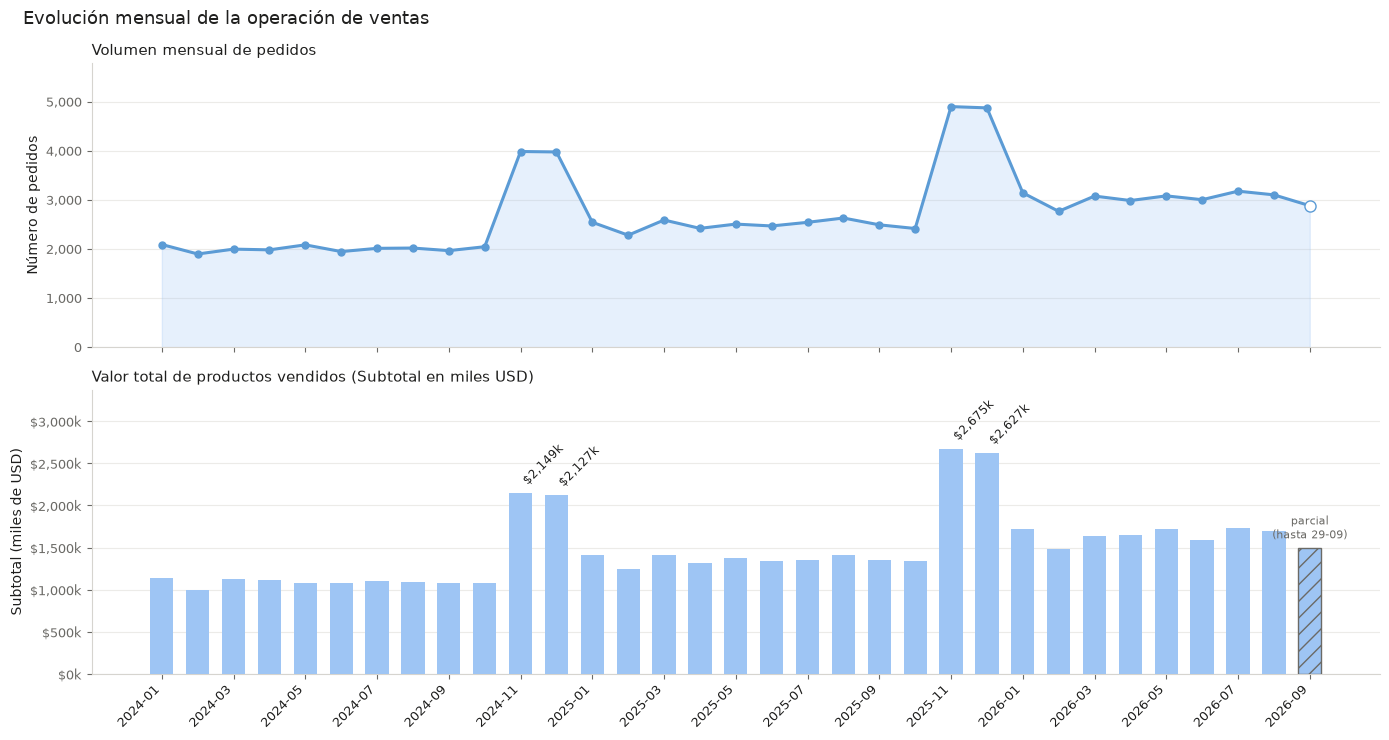

In [232]:
TINTA = globals().get("TINTA", "#1f2421")
TINTA2 = globals().get("TINTA2", "#5c6470")
REJILLA = globals().get("REJILLA", "#e6e8ec")

df_ts = mensual.reset_index().sort_values("mes_compra").copy()
x = np.arange(len(df_ts))
meses = df_ts["mes_compra"].tolist()

fig, axes = plt.subplots(2, 1, figsize=(14, 7.5), sharex=True)

# Volumen de pedidos por mes
ax0 = axes[0]
ax0.plot(x, df_ts["pedidos"], color="#5b9bd5", lw=2.2, marker="o", markersize=5, zorder=3)
ax0.fill_between(x, df_ts["pedidos"], color="#9ec5f4", alpha=0.25, zorder=2)

ax0.set_ylabel("Número de pedidos", color=TINTA, fontsize=10)
ax0.set_title("Volumen mensual de pedidos", loc="left", color=TINTA, fontsize=11)
ax0.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax0.set_ylim(0, df_ts["pedidos"].max() * 1.18)
ax0.grid(axis="y", color=REJILLA)
ax0.set_axisbelow(True)
ax0.spines[["top", "right"]].set_visible(False)
ax0.tick_params(colors=TINTA2, labelsize=9)


# Valor total de productos (Subtotal mensual)
ax1 = axes[1]
ax1.bar(x, df_ts["valor_productos"] / 1_000, color="#9ec5f4", width=0.65, zorder=3)

# Picos estacionales
max_val_k = df_ts["valor_productos"].max() / 1_000
for i, (m, val) in enumerate(zip(meses, df_ts["valor_productos"] / 1_000)):
    if m.endswith(("-11", "-12")):
        ax1.text(
            i, val + max_val_k * 0.025,
            f"${val:,.0f}k",
            ha="left", va="bottom", rotation=45,
            fontsize=8.5, color=TINTA
        )

# Último mes incompleto
fecha_max = orders["order_date"].max()
ax1.patches[-1].set_hatch("//")
ax1.patches[-1].set_edgecolor(TINTA2)
ax0.plot(x[-1], df_ts["pedidos"].iloc[-1], marker="o", markersize=8,
         markerfacecolor="white", markeredgecolor="#5b9bd5", zorder=4)
ax1.text(x[-1], df_ts["valor_productos"].iloc[-1] / 1_000 + max_val_k * 0.025,
         f"parcial\n(hasta {fecha_max:%d-%m})", ha="center", va="bottom", fontsize=8, color=TINTA2)

ax1.set_ylabel("Subtotal (miles de USD)", color=TINTA, fontsize=10)
ax1.set_title("Valor total de productos vendidos (Subtotal en miles USD)", loc="left", color=TINTA, fontsize=11)
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}k"))
ax1.set_ylim(0, max_val_k * 1.26)
ax1.grid(axis="y", color=REJILLA)
ax1.set_axisbelow(True)
ax1.spines[["top", "right"]].set_visible(False)
ax1.tick_params(colors=TINTA2, labelsize=9)

ticks_idx = np.arange(0, len(meses), 2)
ax1.set_xticks(ticks_idx)
ax1.set_xticklabels([meses[i] for i in ticks_idx], rotation=45, ha="right", fontsize=9, color=TINTA)

fig.suptitle("Evolución mensual de la operación de ventas", x=0.02, ha="left", color=TINTA, fontsize=13)
fig.tight_layout()
plt.savefig(RESULTS_DIR / "Serie_tiempo_mensual.png",
            dpi=300,
            bbox_inches="tight")
plt.show(fig)

A partir de las tablas y la figura anteriores encontramos que:

1. La mediana mensual del `subtotal` se mantiene entre \$350.40 y \$390.01 USD durante los 33 meses, sin tendencia. El ticket promedio es consistente con que el crecimiento venga del número de órdenes y no de un ticket mayor.
2. Hay 33 meses consecutivos, de 2024-01 a 2026-09, sin meses faltantes. A nivel diario de los 1,003 días del rango solo 4 no tienen pedidos (el 31 de octubre y el 31 de diciembre de 2024 y de 2025)
3. Hay 0 inconsistencias entre `order_date` y `requested_at` (ninguna devolución precede a su compra) y entre `order_date` y `products.created_at`.
4. Noviembre y diciembre promedian aproximadamente el doble del volumen mensual de enero a octubre (razón de 1.99 en 2024 y 1.96 en 2025). El crecimiento interanual comparable de enero a septiembre es de +24.9 % en pedidos y +24.6 % en subtotal en 2025, y de +21.1 % y +20.7 % en 2026
5. El último pedido es del 29 de septiembre de 2026, así que septiembre es un mes parcial. Además, las órdenes más recientes no han completado su ventana natural de devolución, por lo que su tasa de devolución está subestimada.

In [233]:
# Integridad referencial
fk_items_orders = items["order_id"].isin(orders["order_id"]).mean() * 100
fk_items_products = items["product_id"].isin(products["product_id"]).mean() * 100
fk_returns_items = returns["order_item_id"].isin(items["order_item_id"]).mean() * 100

assert fk_items_orders == 100, f"Huerfanos en items.order_id: {100 - fk_items_orders:.2f}%"
assert fk_items_products == 100, f"Huerfanos en items.product_id: {100 - fk_items_products:.2f}%"
assert fk_returns_items == 100, f"Huerfanos en returns.order_item_id: {100 - fk_returns_items:.2f}%"

# Unicidad en devoluciones por item
dup_returns = returns["order_item_id"].duplicated().sum()

# Violacion en regla de envio grastis y tope de descuento
violacion_envio_gratis = orders[(orders["subtotal"] >= 75) & (orders["shipping_fee"] > 0)].shape[0]
violacion_tope_descuento = orders[orders["discount_amount"] > (0.20 * orders["subtotal"] + 1e-4)].shape[0]

# Devoluciones aprobadas en órdenes canceladas
ret_con_status = returns.merge(
    items[["order_item_id", "order_id"]], on="order_item_id", how="left", validate="many_to_one"
).merge(
    orders[["order_id", "status"]], on="order_id", how="left", suffixes=("_return", "_order"), validate="many_to_one"
)
dev_en_canceladas = ret_con_status[
    (ret_con_status["status_order"] == "cancelled") & (ret_con_status["status_return"] != "rejected")
].shape[0]

auditoria_reglas = pd.DataFrame({
    "Regla_Auditada": [
        "Integridad FK: items a orders ",
        "Integridad FK: items a products",
        "Integridad FK: returns a items",
        "Devoluciones duplicadas por order_item_id",
        "Violaciones regla envío gratis (subtotal >= $75 con shipping > 0)",
        "Violaciones tope de descuento (> 20% del subtotal)",
        "Inconsistencia: devolución no rechazada en orden cancelada"
    ],
    "Resultado": [
        f"{fk_items_orders:.2f}%",
        f"{fk_items_products:.2f}%",
        f"{fk_returns_items:.2f}%",
        dup_returns,
        violacion_envio_gratis,
        violacion_tope_descuento,
        dev_en_canceladas
    ]
})

display(auditoria_reglas)

,Regla_Auditada,Resultado
0,Integridad FK: items a orders,100.00%
1,Integridad FK: items a products,100.00%
2,Integridad FK: returns a items,100.00%
3,Devoluciones duplicadas por order_item_id,0
4,Violaciones regla envío gratis (subtotal >= $7...,0
5,Violaciones tope de descuento (> 20% del subto...,0
6,Inconsistencia: devolución no rechazada en ord...,0


Al revisar los resultados, podemos observar que las relaciones entre las tablas presentan un buen nivel de consistencia. Las tres revisiones de integridad muestran un resultado del 100%, lo que significa que todos los registros de artículos estan relacionados con una orden y un producto existentes y que todas las devoluciones estan relacionadas con un artículo registrado. Esto nos indica que no se encontraron registros que hagan referencia a información inexistente en estas relaciones.

No se encontraron devoluciones duplicadas para un mismo articulo, ya que el resultado fue de cero. Esto es importante porque ayuda a evitar que una misma compra aparezca repetida en los registros de devoluciones y pueda alterar los resultados de los análisis posteriores.

También se revisaron algunas reglas relacionadas con las condiciones de venta. En el caso de los envíos gratuitos, no se encontraron órdenes que incumplieran la regla establecida y no se identificaron descuentos que superaran el límite permitido del 20% del subtotal. Esto muestra que los registros revisados respetan las condiciones comerciales definidas para estas operaciones.

Finalmente, se verificó que no existieran inconsistencias entre las devoluciones y el estado de las órdenes. El resultado fue de cero casos, por lo que no se encontraron registros que incumplieran esta regla.

### **3.3 Auditorias finacieras**

**Análisis de Consistencia de Facturación**

In [234]:
# Obtener copia de la tabla de órdenes para la auditoría
ord_auditoria = TABLAS["orders"].copy()

# Calcular el total teórico esperado según la ecuación de negocio
ord_auditoria["total_calculado"] = (
    ord_auditoria["subtotal"]
    - ord_auditoria["discount_amount"]
    + ord_auditoria["shipping_fee"]
    + ord_auditoria["tax_amount"]
)

# Determinar la diferencia absoluta para evitar errores de precisión por punto flotante (float)
ord_auditoria["diferencia"] = (ord_auditoria["total_amount"] - ord_auditoria["total_calculado"]).abs()

# Definir tolerancia de 1 centavo ($0.01)
tolerancia = 0.01
inconsistencias = ord_auditoria[ord_auditoria["diferencia"] > tolerancia]

# Mostrar resumen del control
print(f"Total de pedidos analizados: {len(ord_auditoria):,}")
print(f"Pedidos con inconsistencias detectadas: {len(inconsistencias)}")

if len(inconsistencias) > 0:
    display(inconsistencias[["order_id", "subtotal", "discount_amount", "shipping_fee", "tax_amount", "total_amount", "total_calculado", "diferencia"]].head())
else:
    print("Todos los registros coinciden con la ecuación matemática esperada.")

Total de pedidos analizados: 90,000
Pedidos con inconsistencias detectadas: 0
Todos los registros coinciden con la ecuación matemática esperada.


### 3.4 Análisis de Consistencia de Facturación (Auditoría de Variables)

Para validar la integridad de las variables financieras de la tabla `orders`, se evaluó de forma sistemática la ecuación fundamental de facturación en cada una de las compras:

$$\text{total\_amount} = \text{subtotal} - \text{discount\_amount} + \text{shipping\_fee} + \text{tax\_amount}$$

**Conclusiones de la auditoría:**
1. **Consistencia Absoluta:** De los **90,000 pedidos** procesados en el conjunto de datos, **ninguno** presenta diferencias significativas (mayores a $0.01) con respecto al total calculado.
2. **Mitigación de Errores de Redondeo:** La tolerancia establecida de un centavo ($0.01) absorbe de manera segura las diferencias inherentes a la representación de números decimales de punto flotante en sistemas computacionales, demostrando que no existen desviaciones en la lógica aplicada.
3. **Calidad de los Datos:** Este resultado confirma que no existen inconsistencias en la captura, cálculo o transferencia de importes monetarios en el canal de ventas del ecommerce, asegurando una base sólida y confiable para análisis financieros posteriores.

### 3.5 Auditorías de Consistencia Adicionales (Calidad de Datos)

Para robustecer la auditoría del conjunto de datos minorista, realizaremos las siguientes validaciones cruzadas:
1. **Precios de Venta vs. Catálogo:** Asegurar que el precio unitario cobrado coincida con el precio maestro del producto.
2. **Cálculo de Totales de Línea:** Verificar que `line_total` sea exactamente `quantity` * `unit_price`.
3. **Límite de Reembolsos:** Confirmar que no existan reembolsos superiores al costo total de la línea de producto devuelta.

In [235]:
# 1. Auditoría de Precios Unitarios (Items vs Products)

items_prod = TABLAS["items"].merge(
    products_clean[["product_id", "unit_price"]],
    on="product_id",
    suffixes=("_cobrado", "_catalogo")
)

items_prod["dif_precio"] = (
    items_prod["unit_price_cobrado"] - items_prod["unit_price_catalogo"]
).abs()

precios_inconsistentes = items_prod[items_prod["dif_precio"] > 0.01]

print(f"1. Ítems con precio cobrado diferente al catálogo: {len(precios_inconsistentes)}")


# 2. Auditoría de Totales de Línea

items_calc = TABLAS["items"].copy()

items_calc["line_total_esperado"] = (
    items_calc["quantity"] * items_calc["unit_price"]
)

items_calc["dif_linea"] = (
    items_calc["line_total"] - items_calc["line_total_esperado"]
).abs()

lineas_inconsistentes = items_calc[items_calc["dif_linea"] > 0.01]

print(f"2. Ítems con error en el cálculo de line_total: {len(lineas_inconsistentes)}")


# 3. Auditoría de Límites de Reembolso

returns_audit = TABLAS["returns"].merge(
    TABLAS["items"][["order_item_id", "line_total"]],
    on="order_item_id",
    how="inner"
)

returns_audit["sobregiro_reembolso"] = (
    returns_audit["refund_amount"] - returns_audit["line_total"]
)

reembolsos_excedidos = returns_audit[
    returns_audit["sobregiro_reembolso"] > 0.01
]

print(
    f"3. Devoluciones con monto de reembolso mayor al pagado por la línea: "
    f"{len(reembolsos_excedidos)}"
)

1. Ítems con precio cobrado diferente al catálogo: 0
2. Ítems con error en el cálculo de line_total: 0
3. Devoluciones con monto de reembolso mayor al pagado por la línea: 0


### Segmentación y Filtrado de Pedidos Mayoristas (Enfoque en Comercio Minorista)

Para asegurar que nuestro análisis describa fielmente el comportamiento del **comercio minorista (retail)**, es fundamental identificar y excluir aquellas transacciones de volumen o valor excepcionalmente altos que corresponden a compras corporativas o mayoristas.

A continuación, analizaremos los percentiles de las variables `subtotal` en las órdenes y `quantity` en los ítems para establecer un umbral de corte objetivo.

In [236]:
# 1. Analizar la distribución de los montos de compra altos (percentiles 95 a 99.9)

percentiles_subtotal = TABLAS["orders"]["subtotal"].quantile([0.95, 0.99, 0.995, 0.999])

print("Percentiles del Subtotal en Órdenes:")
print(percentiles_subtotal.round(2))


# 2. Analizar el volumen de ítems por orden

cantidad_por_orden = (TABLAS["items"].groupby("order_id")["quantity"].sum())

percentiles_cantidad = cantidad_por_orden.quantile([0.95, 0.99, 0.995, 0.999])

print("\nPercentiles de Cantidad Total de Productos por Orden:")
print(percentiles_cantidad.round(2))

Percentiles del Subtotal en Órdenes:
0.950    1584.97
0.990    2649.23
0.995    3259.50
0.999    4647.60
Name: subtotal, dtype: float64

Percentiles de Cantidad Total de Productos por Orden:
0.950     9.0
0.990    12.0
0.995    13.0
0.999    16.0
Name: quantity, dtype: float64


In [237]:
# 3. Definición de umbrales para el perfil minorista

# Utilizaremos el percentil 99.5% como límite superior práctico para compras minoristas.
# Compras por encima de este límite se clasifican como posibles operaciones mayoristas/corporativas.

UMBRAL_SUBTOTAL = TABLAS["orders"]["subtotal"].quantile(0.995)
UMBRAL_CANTIDAD = cantidad_por_orden.quantile(0.995)

print(f"Umbral de corte de subtotal (99.5%): ${UMBRAL_SUBTOTAL:,.2f} USD")
print(f"Umbral de corte de cantidad de productos (99.5%): {UMBRAL_CANTIDAD} unidades")


# Identificar órdenes que exceden los límites minoristas

ordenes_mayoristas_monto = TABLAS["orders"][
    TABLAS["orders"]["subtotal"] > UMBRAL_SUBTOTAL
]["order_id"]

ordenes_mayoristas_cantidad = cantidad_por_orden[
    cantidad_por_orden > UMBRAL_CANTIDAD
].index

ordenes_mayoristas_ids = set(ordenes_mayoristas_monto).union(
    set(ordenes_mayoristas_cantidad)
)


# 4. Aplicar el filtro para quedarnos únicamente con pedidos minoristas

orders_retail = TABLAS["orders"][
    ~TABLAS["orders"]["order_id"].isin(ordenes_mayoristas_ids)
].copy()

items_retail = TABLAS["items"][
    ~TABLAS["items"]["order_id"].isin(ordenes_mayoristas_ids)
].copy()


# Resumen de filtrado

print("\n--- Resumen de Filtrado ---")
print(f"Pedidos mayoristas excluidos: {len(ordenes_mayoristas_ids):,}")
print(f"Pedidos minoristas (retail) conservados: {len(orders_retail):,} "
      f"({len(orders_retail)/len(TABLAS['orders'])*100:.2f}% del total)")

Umbral de corte de subtotal (99.5%): $3,259.50 USD
Umbral de corte de cantidad de productos (99.5%): 13.0 unidades



--- Resumen de Filtrado ---
Pedidos mayoristas excluidos: 705
Pedidos minoristas (retail) conservados: 89,295 (99.22% del total)


Con el objetivo de enfocar el análisis en el comportamiento del comercio minorista (retail) y evitar que transacciones de volumen atípico distorsionen los resultados, se aplicó una estrategia de segmentación basada en umbrales estadísticos objetivos:

1.-Definición de Umbrales (Percentil 99.5%):

2.-Monto de compra (Subtotal): Se decidio establecer un límite superior de $3,259.50 USD por pedido.
Volumen de productos (Cantidad): Se decidio establecer un un límite de 13 unidades totales por orden.
Resultados del Filtrado:

Pedidos Mayoristas Excluidos: Se identificaron y separaron 705 pedidos que superaban alguno de los dos umbrales (0.78% de las transacciones totales).
Pedidos Minoristas Conservados: Se mantuvieron 89,295 pedidos, lo que representa el 99.22% del total original.
Este proceso garantiza que la base de datos resultante (orders_retail e items_retail) represente de manera fiel y limpia la dinámica del cliente minorista, protegiendo las estadísticas clave (como promedios y distribuciones) de sesgos provocados por compras institucionales o de gran volumen.

### Conclusión

Después de revisar la calidad de la información, podemos concluir que en general los datos presentan buenas condiciones para continuar con nuestro análisis. Se revisaron los valores faltantes, los registros duplicados, los tipos de datos, las relaciones entre las tablas, las fechas y la consistencia de los importes. Estas revisiones nos permitieron conocer mejor la información e identificar qué aspectos necesitaban atención antes de comenzar con el análisis.
Durante este proceso tomamos dos decisiones importantes para preparar los datos de acuerdo con los objetivos del proyecto.

**Primera decisión: excluir la variable del peso de los productos (weight_kg)**

Identificamos que esta variable tenía 78 valores faltantes de un total de 1,500 productos, lo que representa el 5.20%. Para decidir qué hacer con ellos, revisamos cómo se distribuían los pesos entre las categorías y si tenían alguna relación importante con otras variables, como el precio, el costo, la utilidad y las devoluciones.

Los resultados mostraron que las diferencias de peso entre categorías eran relativamente pequeñas y que su relación con las demás variables era muy baja. Por esta razón, decidimos no completar los datos faltantes con valores estimados y tampoco conservar esta variable para los análisis posteriores.

**Segunda decisión: separar los pedidos con montos o cantidades excepcionalmente altos.**

Al revisar los valores extremos, encontramos que algunas compras tenían importes o cantidades de productos mucho mayores que las habituales. Sin embargo, consideramos que estos registros no necesariamente eran errores, por lo que decidimos conservarlos en las tablas originales.

Como el objetivo del proyecto está enfocado en el comportamiento del comercio minorista, realizamos una separación utilizando como referencia el percentil 99.5% del monto de compra y de la cantidad de productos por pedido. Con estos límites identificamos 705 pedidos que superaban al menos uno de los dos valores establecidos, lo que representa el 0.78% del total. Los 89,295 pedidos restantes, equivalentes al 99.22%, se conservaron en las nuevas tablas de trabajo para el análisis retail.

Es importante mencionar que estos pedidos se consideran transacciones de valor o volumen excepcionalmente alto, pero no podemos asegurar que todos sean compras mayoristas o corporativas, ya que no contamos con información que confirme el tipo de cliente. Por ello, esta separación se realizó para enfocar el análisis, no porque consideremos que esos registros sean incorrectos.


---

## 4. Visualización de los datos

<details open>
  <summary><b>1.1 Planteamiento y visualización pregunta 1</b></summary>
  
**¿Cómo interactúan los descuentos promocionales (discount_amount)
con el umbral de envío gratuito de $75 USD (shipping_fee = 0), y en qué segmentos de órdenes la coincidencia de alto descuento y exención de tarifa de envío erosiona críticamente el margen bruto?**

Si una orden cuenta con envío gratuito y además tiene aplicado un descuento, la tienda asume ambos costes al mismo tiempo. Esto significa que no solo deja de ingresar parte del importe de la venta, sino que también cubre el coste del envío, reduciendo el margen obtenido en ese pedido.

Lo que queremos encontrar es en qué combinación de tamaño de pedido y tamaño de descuento la tienda pierde más ganancia.

Para visualizar esta pregunta, primero creamos las variables que son relevantes para el problema:

### Variables principales:

| Variable | Tabla | Cálculo | Descripción |
|---|---|---|---|
| `tasa_efectiva_descuento` | `orders_retail` | `discount_amount` ÷ `subtotal` | Proporción del subtotal que se descontó.|
| `utilidad_bruta_orden` | `orders_retail` | `utilidad_antes_desc` − `discount_amount` | Ganancia de la orden después del descuento.|
| `costo_envio_absorbido` | `orders_retail` | \$7.48 si `envio_gratis` = 1; 0 si no | Costo de envío que paga la tienda. **Supuesto:** promedio de la tarifa cobrada a órdenes que sí pagan envío. |
| `margen_con_envio` | `orders_retail` | (`utilidad_bruta_orden` − `costo_envio_absorbido`) ÷ `venta_neta` | **Variable principal.** Margen considerando a la vez el descuento y el envío gratis. |
| `tramo_subtotal` | `orders_retail` | Cortes del `subtotal`: < \$60, \$60–74.99, \$75–90, > \$90 | Segmento según el monto de compra antes del descuento. Renglones de la matriz. |
| `nivel_descuento` | `orders_retail` | Cortes de `tasa_efectiva_descuento`: 0%, 1–10%, 11–20% | Segmento según el tamaño del descuento. Columnas de la matriz. |


In [238]:
# Vamos a calcular las siguientes variables:

# ¿Cuánto gana la tienda con cada producto vendido?

# Variables para items_retail
items_retail = items_retail.merge(products_clean[["product_id", "unit_cost"]], on="product_id", how="left",
                    validate="many_to_one")
items_retail["costo_fila"] = items_retail["quantity"] * items_retail["unit_cost"] # La fila es la combinación de la cantidad por el precio
items_retail["utilidad_fila"] = items_retail["line_total"] - items_retail["costo_fila"]

# Variables para orders_retail
util_items = items_retail.groupby("order_id")["utilidad_fila"].sum()
orders_retail["utilidad_antes_desc"] = orders_retail["order_id"].map(util_items)

orders_retail["tasa_efectiva_descuento"] = orders_retail["discount_amount"] / orders_retail["subtotal"]
orders_retail["utilidad_bruta_orden"] = orders_retail["utilidad_antes_desc"] - orders_retail["discount_amount"]

orders_retail["venta_neta"] = orders_retail["subtotal"] - orders_retail["discount_amount"]
orders_retail["margen_sin_envio"] = orders_retail["utilidad_bruta_orden"] / orders_retail["venta_neta"]

# Envío
orders_retail["envio_gratis"] = (orders_retail["shipping_fee"] == 0).astype(int)
# Caso clave: el umbral se evalúa sobre el subtotal ANTES del descuento,
# así que hay órdenes que pagan < $75 y aun así reciben envío gratis
orders_retail["doble_beneficio"] = ((orders_retail["envio_gratis"] == 1) &
                             (orders_retail["venta_neta"] < 75)).astype(int)

# Margen ajustado por envío (SUPUESTO): no hay costo real de paquetería en la base;
# se usa la tarifa promedio que pagan las órdenes con envío como costo que absorbe la tienda
COSTO_ENVIO_EST = orders_retail.loc[orders_retail["shipping_fee"] > 0, "shipping_fee"].mean()
orders_retail["costo_envio_absorbido"] = np.where(orders_retail["envio_gratis"] == 1, COSTO_ENVIO_EST, 0)
orders_retail["utilidad_ajustada_envio"] = orders_retail["utilidad_bruta_orden"] - orders_retail["costo_envio_absorbido"]
orders_retail["margen_con_envio"] = orders_retail["utilidad_ajustada_envio"] / orders_retail["venta_neta"]

# Tramos de la matriz
orders_retail["tramo_subtotal"] = pd.cut(orders_retail["subtotal"], [0, 60, 75, 90.0001, np.inf], right=False,
                                  labels=["< $60", "$60–74.99", "$75–90", "> $90"])
orders_retail["nivel_descuento"] = pd.cut(orders_retail["tasa_efectiva_descuento"], [-0.001, 0, 0.10, 0.2001],
                                   labels=["0%", "1–10%", "11–20%"])

# Respecto a las devoluciones: Sólo vamos a contar los reembolsos aprobados y regresados para poder restarlos de la ganancia de las
# ordenes y saber cuánto en realidad ganó la tienda

# returns no tiene order_id, solo order_item_id -> lo traemos de items con un merge
reemb = (returns[returns["status"].isin(["approved", "refunded"])]
         .merge(items_retail[["order_item_id", "order_id"]], on="order_item_id")
         .groupby("order_id")["refund_amount"].sum())

# Las órdenes sin devolución quedan con 0 (fillna)
orders_retail["reembolso"] = orders_retail["order_id"].map(reemb).fillna(0)

# Utilidad y margen ya descontando lo reembolsado
orders_retail["utilidad_neta_devol"] = orders_retail["utilidad_ajustada_envio"] - orders_retail["reembolso"]
orders_retail["margen_neto"] = orders_retail["utilidad_neta_devol"] / orders_retail["venta_neta"]

# "returned" SÍ se queda, porque su devolución ya se descontó
ventas = orders_retail[orders_retail["status"].isin(["delivered", "shipped", "returned"])].copy()

### Elementos para para la matriz usada en el mapa de calor:


In [239]:
# Creamos una función ya que vamos a usarla más de una vez para
def matriz(col):
    return ventas.pivot_table(index="tramo_subtotal", # renglones
                              columns="nivel_descuento", # columnas
                              values=col, # variable
                              aggfunc="mean", # función de agregación
                              observed=True) # combinaciones que cumplen la condición

conteo = pd.crosstab(ventas["tramo_subtotal"], ventas["nivel_descuento"]) # Cuenta las órdenes

m_margen = matriz("margen_sin_envio") # Lo que el cliente pago menos costo del produco
m_ajust = matriz("margen_con_envio") # margen bruto menos el costo del envío por ser gratis para el cliente
m_neto = matriz("margen_neto") # margen ajustado menos el dinero que se reembolsó

display("Órdenes por celda: ", conteo)
print("------------------------------------")
display("Margen bruto: ", (m_margen * 100).round(1))
print("------------------------------------")
display(f"Margen ajustado por envío % (costo envío estimado ${COSTO_ENVIO_EST:.2f})",(m_ajust * 100).round(1))
print("------------------------------------")
display("Margen neto después de envío y devoluciones: %", (m_neto * 100).round(1), )
print("------------------------------------")
display("Diferencia por devoluciones (puntos %)", ((m_neto - m_ajust) * 100).round(1))
print("------------------------------------")
print("Órdenes con doble beneficio:", ventas["doble_beneficio"].sum()) # vale 1 si la orden tuvo envío
                                                                        #gratis pero pagó menos de $75 después del descuento, y 0 si no.

'Órdenes por celda: '

nivel_descuento,0%,1–10%,11–20%
tramo_subtotal,,,
< $60,4470,394,726
$60–74.99,1311,111,206
$75–90,1566,122,254
> $90,59099,5013,9952


------------------------------------


'Margen bruto: '

nivel_descuento,0%,1–10%,11–20%
tramo_subtotal,,,
< $60,48.1,43.6,38.7
$60–74.99,46.4,43.5,35.1
$75–90,51.0,47.4,42.4
> $90,47.9,43.5,38.6


------------------------------------


... (5 outputs left out)

------------------------------------


'Diferencia por devoluciones (puntos %)'

nivel_descuento,0%,1–10%,11–20%
tramo_subtotal,,,
< $60,-2.8,-4.7,-3.2
$60–74.99,-3.4,-2.4,-5.4
$75–90,-3.0,-2.8,-2.9
> $90,-2.7,-3.2,-3.3


------------------------------------
Órdenes con doble beneficio: 305


Veamos estos resultados visualmente:

In [240]:
# 1) sin envío            = (pagó el cliente − costo productos) / pagó el cliente
# 2) con envío            = lo anterior − envío que absorbe la tienda
# 3) con envío y devol.   = lo anterior − reembolsos

TINTA, TINTA2, REJILLA, ROJO = "#1f1f1e", "#6b6a66", "#ecebe8", "#c0392b"
# Un solo tono azul, de claro a oscuro: más oscuro = más gastos restados
C_SIN, C_ENV, C_DEV = "#86b6ef", "#2a78d6", "#0d366b"
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.edgecolor": "#d6d4cf",
                     "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2})

MARGENES = [("margen_sin_envio", "1) Sin descontar envío (margen bruto)", C_SIN),
            ("margen_con_envio", "2) Envío gratis >= $75 (margen ajustado)", C_ENV),
            ("margen_neto", "3) Envío gratis y devoluciones (margen neto)", C_DEV)]


def tabla(col):
    return ventas.pivot_table(index="tramo_subtotal", columns="nivel_descuento", values=col,
                              aggfunc="mean", observed=True) * 100


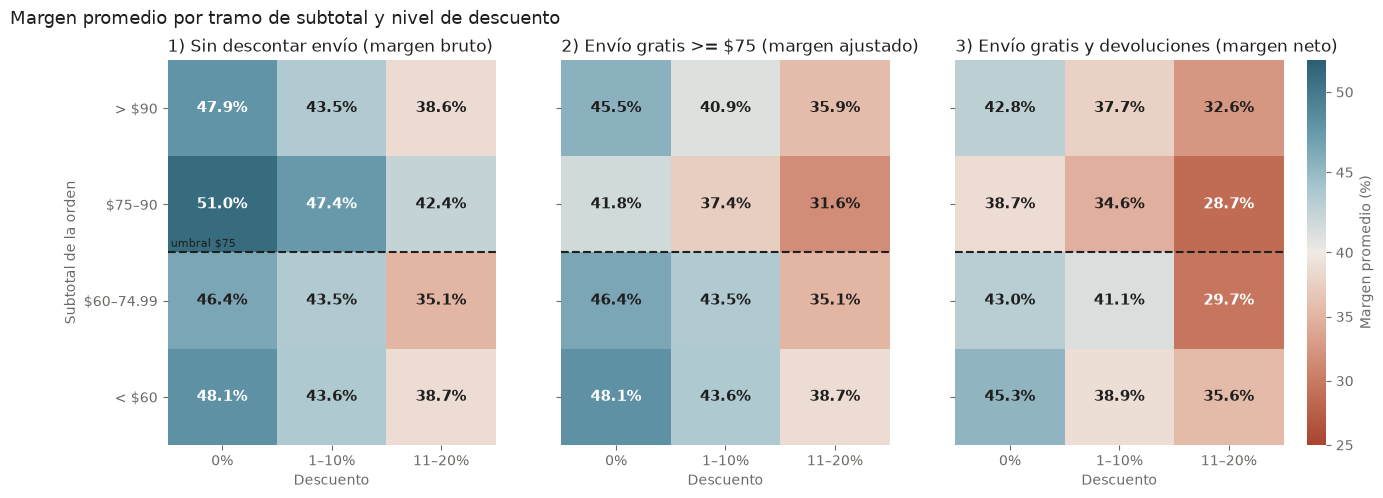

In [241]:
#Gráfica de mapa de calor
cmap = LinearSegmentedColormap.from_list(
    "divergente", ["#a8442f", "#c97b63", "#e3b4a2", "#efeae4", "#a9c6cf", "#5f93a5", "#2c5f73"])
VMIN, VMAX = 25, 52
norma = TwoSlopeNorm(vmin=VMIN, vcenter=40, vmax=VMAX)
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, (col, titulo, _) in zip(axes, MARGENES):
    m = tabla(col).iloc[::-1]                       # tramo más alto arriba
    im = ax.imshow(m.values, cmap=cmap, norm=norma, aspect="auto")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.values[i, j]
            ax.text(j, i, f"{v:.1f}%", ha="center", va="center", fontsize=11, fontweight="bold",
                    color="white" if abs(norma(v) - 0.5) > 0.3 else TINTA)
    ax.set_xticks(range(m.shape[1]), m.columns)
    ax.set_yticks(range(m.shape[0]), m.index)
    ax.axhline(1.5, color=TINTA, lw=1.5, ls="--")   # umbral $75
    ax.set_title(titulo, loc="left", color=TINTA, fontsize=12)
    ax.set_xlabel("Descuento")
    for s in ax.spines.values():
        s.set_visible(False)
axes[0].set_ylabel("Subtotal de la orden")
axes[0].text(-0.47, 1.47, "umbral $75", color=TINTA, va="bottom", fontsize=8)
cb = fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02)
cb.set_label("Margen promedio (%)", color=TINTA2)
cb.outline.set_visible(False)
fig.suptitle("Margen promedio por tramo de subtotal y nivel de descuento",
             x=0.02, ha="left", color=TINTA, fontsize=13)
fig.savefig("Mapas de calor.png", dpi=160, bbox_inches="tight")
plt.savefig(RESULTS_DIR / "Margen promedio por tramo de subtotal y nivel de descuento.png",
            dpi=300,
            bbox_inches="tight")
plt.show(fig)

### Observaciones adicionales al gráfico de mapa de calor:
 - Observación 1. <br>
 Veamos la diferencia de margen que tienen las órdenes con **descuento alto** comparadas con las que **no tienen descuento**.

In [242]:
caida_desc = pd.DataFrame({
    "Sin envío":      (m_margen["0%"] - m_margen["11–20%"]) * 100,
    "Con envío":      (m_ajust["0%"]  - m_ajust["11–20%"])  * 100,
    "Envío y devol.": (m_neto["0%"]   - m_neto["11–20%"])   * 100,
}).round(1)

print("Diferencia de margen entre órdenes sin descuento y con descuento de 11–20% (puntos)")
display(caida_desc)
print(f"Rango de la caída del margen: de {caida_desc.min().min()} a {caida_desc.max().max()} puntos")

Diferencia de margen entre órdenes sin descuento y con descuento de 11–20% (puntos)


,Sin envío,Con envío,Envío y devol.
tramo_subtotal,,,
< $60,9.4,9.4,9.8
$60–74.99,11.3,11.3,13.4
$75–90,8.6,10.2,10.1
> $90,9.3,9.7,10.3


Rango de la caída del margen: de 8.6 a 13.4 puntos


Por ejemplo: En la celda donde vimos menor margen fue la que se encuentra en el panel 3, rango de subtotal $75-90 y descuento de 11-20%
<br> Esta celda tiene los siguientes márgenes:
- 38.7% cuando se aplica el envío gratis, pero no hay descuento aplicado al subtotal.
- 28.7% cuando se aplica envío gratis y un descuento de 11-20%
<br> <br> Lo que vemos en la tabla, es la diferencia para cada matriz/panel.
<br> En este caso, 38.7-28.7=10 que es aproximadamente el resultado que nos da la tabla de 10.1

 - Observación 2. <br>
 Comparamos el costo del envío por tramo. Recordando el **supuesto** que el **costo de envío de paquetería es el promedio de la tarifa cobrada a órdenes que sí pagan envío**.
 <br>Veamos el tramo donde se está aplicando el descuento más alto de 11-20% para que la única diferencia que analicemos sea el tamaño del subtotal.

In [243]:
# Por tramo (solo descuento 11–20%): compra promedio, envío como % del subtotal y margen con envío
alto = ventas[ventas["nivel_descuento"] == "11–20%"]
envio_tramo = alto.groupby("tramo_subtotal", observed=True).agg(
    ordenes=("order_id", "size"), # cuenta las órdenes en el tramo
    compra_promedio=("subtotal", "mean"), # subtotal promedio del tramo
    envio_total=("costo_envio_absorbido", "sum"), # Envío pagado por la tienda en ese tramo
    subtotal_total=("subtotal", "sum"), # Todo el subtotal del tramo
    margen_con_envio=("margen_con_envio", "mean"), # el margen promedio con envío
)
# Envío como % del subtotal = envío total del segmento / subtotal total del segmento
envio_tramo["% envio subtotal"] = envio_tramo["envio_total"] / envio_tramo["subtotal_total"] * 100
envio_tramo["margen_con_envio"] = envio_tramo["margen_con_envio"] * 100

print("Importancia del costo del envío por tramo (órdenes con descuento 11–20%)")
display(envio_tramo[["ordenes", "compra_promedio", "% envio subtotal", "margen_con_envio"]].round(1))
# Debajo de $75 el envío es 0%: el cliente lo paga y la tienda no absorbe nada

Importancia del costo del envío por tramo (órdenes con descuento 11–20%)


,ordenes,compra_promedio,% envio subtotal,margen_con_envio
tramo_subtotal,,,,
< $60,726,36.5,0.0,38.7
$60–74.99,206,68.4,0.0,35.1
$75–90,254,81.2,9.2,31.6
> $90,9952,569.8,1.3,35.9


  - Debajo de \$75 el envío pesa 0%. El cliente lo paga.
  - El el tramo de \$75-90, el envío representa el 9.2% del subtotal.
  - En más de \$90, el subtotal promedio es de \$569.8 y el envío representa el 1.3%. Por eso, el margen se recupera.

 - Observación 3.<br>Reembolsos o devoluciones<br>
 Observemos que cuando hay reembolsos, la diferencia no es muy significativa de la matriz/panel 2 (considerando envíos gratis) a la matriz/panel 3 (considerando envíos gratis y reembolsos).

In [244]:
# Puntos que disminuyen el margen en cada celda al restar reembolsos
dif_devol = ((m_neto - m_ajust) * 100).round(1)
print("Puntos de margen que restan las devoluciones, por celda")
display(dif_devol)
print(f"Rango: de {dif_devol.min().min()} a {dif_devol.max().max()} puntos")
print("------------------------------------")

# Frecuencia y porcentaje de las devoluciones en cada celda
ventas["tuvo_reembolso"] = (ventas["reembolso"] > 0).astype(int)
g = ventas.groupby(["tramo_subtotal", "nivel_descuento"], observed=True)
pct_ordenes_reemb = (g["tuvo_reembolso"].mean() * 100).unstack().round(1)
pct_dinero_reemb = (g["reembolso"].sum() / g["venta_neta"].sum() * 100).unstack().round(1)

print("% de órdenes con reembolso, por celda")
display(pct_ordenes_reemb)

print("------------------------------------")

print("Reembolso como % de la venta neta, por celda")
display(pct_dinero_reemb)

total_pct_ordenes = ventas["tuvo_reembolso"].mean() * 100
total_pct_dinero = ventas["reembolso"].sum() / ventas["venta_neta"].sum() * 100
print(f"En total: {total_pct_ordenes:.1f}% de las órdenes tuvo reembolso, "
      f"equivalente a {total_pct_dinero:.1f}% de la venta neta\n")


Puntos de margen que restan las devoluciones, por celda


nivel_descuento,0%,1–10%,11–20%
tramo_subtotal,,,
< $60,-2.8,-4.7,-3.2
$60–74.99,-3.4,-2.4,-5.4
$75–90,-3.0,-2.8,-2.9
> $90,-2.7,-3.2,-3.3


Rango: de -5.4 a -2.4 puntos
------------------------------------
% de órdenes con reembolso, por celda


nivel_descuento,0%,1–10%,11–20%
tramo_subtotal,,,
< $60,3.8,5.6,3.7
$60–74.99,5.0,3.6,6.3
$75–90,4.5,4.9,3.9
> $90,5.6,6.1,5.6


------------------------------------
Reembolso como % de la venta neta, por celda


nivel_descuento,0%,1–10%,11–20%
tramo_subtotal,,,
< $60,2.7,5.4,3.6
$60–74.99,3.3,2.5,5.3
$75–90,3.1,2.7,2.9
> $90,2.7,3.0,3.3


En total: 5.5% de las órdenes tuvo reembolso, equivalente a 2.8% de la venta neta



## Grafica 1. Margen promedio por tramo de subtotal y nivel de descuento (Mapa de calor)

La figura presenta tres mapas de calor con la misma estructura. Los renglones son tramos de subtotal (el monto de la compra a precio de lista, antes de descuento, envío e impuestos). Las columnas son niveles de tasa efectiva de descuento. Cada celda muestra el margen promedio de las órdenes de esa combinación, calculado sobre lo que pagó el cliente. La línea punteada marca el umbral de $75, a partir del cual la tienda otorga envío gratis. Los tonos azules indican márgenes superiores a 40% y los tonos terracota, inferiores.

Los tres paneles calculan el mismo margen, restando en cada uno un gasto adicional:

1. **Margen bruto:** solo descuenta el costo de los productos y el descuento. Es la fórmula planteada originalmente.
2. **Margen ajustado:** además resta un costo estimado de envío a las órdenes con envío gratis (subtotal de $75 o más).
3. **Margen neto:** además resta los reembolsos por devoluciones aprobadas o pagadas.

Se observan dos patrones.

Primero, en todos los tramos el margen disminuye conforme aumenta el descuento: en órdenes menores a $60 pasa de 48.1% sin descuento a 38.7% con descuento de 11–20%.

Segundo, una vez considerado el costo de envío (panel 2), el margen cae al cruzar el umbral de \$75. El tramo de \$75–90 queda por debajo del de \$60–74.99 en los tres niveles de descuento: 41.8% contra 46.4%, 37.4% contra 43.5% y 31.6% contra 35.1%.

El segmento más afectado es el que combina ambas condiciones, compras de \$75 a \$90 con descuento de 11%–20%, con un margen ajustado de 31.6%. Al descontar las devoluciones (panel 3), todos los márgenes bajan entre 2.4 y 5.4 puntos (alrededor de 3 en la mayoría), pero ese segmento sigue siendo el de menor margen (28.7%).

En el panel 1, el tramo de \$75–90 aparece como el más rentable (51.0% sin descuento), y sólo al incorporar el costo del envío se revela como el más vulnerable. Esto muestra que medir la rentabilidad sin considerar el envío gratis lleva a una conclusión equivocada. Además, el umbral se evalúa sobre el subtotal antes del descuento: una compra de \$80 con 15% de descuento paga \$68 y aun así recibe envío gratis. Esto sugiere posibles ajustes de política comercial, como calcular el umbral sobre el monto ya descontado, limitar los descuentos altos en compras cercanas a \$75 o revisar el monto del umbral.

**Limitaciones**

- La base no registra el costo real de paquetería. Se usó como aproximación la tarifa promedio cobrada a las órdenes que sí pagan envío (\$7.48), un mismo valor para todas las órdenes, sin distinguir peso, destino ni transportista.

- Las celdas tienen tamaños muy distintos: el tramo mayor a $90 concentra cerca del 89% de las órdenes, mientras que algunas celdas de los tramos bajos tienen poco más de 100. Los promedios de esas celdas son menos estables.

- El margen neto supone que el monto reembolsado se pierde por completo. Si el producto devuelto regresa al inventario y se revende, la pérdida real es menor.

- Los valores son promedios por orden, por lo que cada orden pesa igual independientemente de su monto.

- El análisis es descriptivo: muestra asociaciones, no prueba que el descuento o el envío causen la caída del margen.


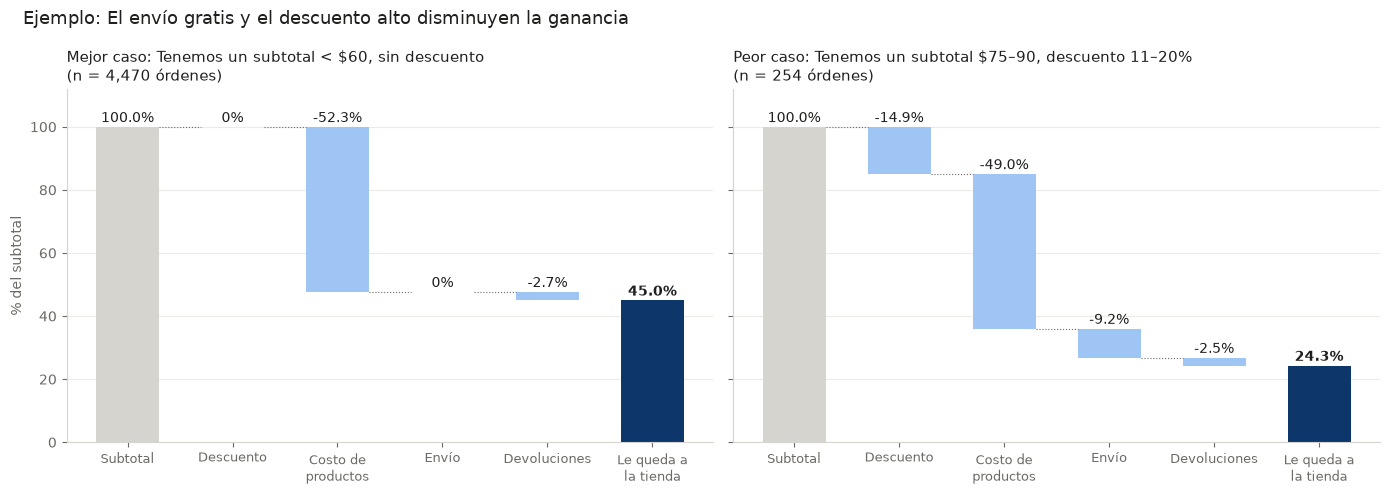

In [245]:
# Gráfica de cascada
def cascada(ax, tramo, nivel, titulo):
    d = ventas[(ventas["tramo_subtotal"] == tramo) & (ventas["nivel_descuento"] == nivel)]
    base = d["subtotal"].sum() / 100
    desc = d["discount_amount"].sum() / base
    costo = (d["subtotal"].sum() - d["utilidad_antes_desc"].sum()) / base
    envio = d["costo_envio_absorbido"].sum() / base
    devol = d["reembolso"].sum() / base
    queda = 100 - desc - costo - envio - devol
    pasos = [("Subtotal", 100), ("Descuento", -desc), ("Costo de\nproductos", -costo),
             ("Envío", -envio), ("Devoluciones", -devol), ("Le queda a\nla tienda", queda)]
    nivel_actual = 100
    for i, (nom, v) in enumerate(pasos):
        if i == 0:
            ax.bar(i, v, color="#d6d4cf", width=0.6); arriba = v
        elif i == len(pasos) - 1:
            ax.bar(i, v, color=C_DEV, width=0.6); arriba = v
        else:
            ax.bar(i, -v, bottom=nivel_actual + v, color="#9ec5f4", width=0.6)
            arriba = nivel_actual
            ax.plot([i - 1 + 0.3, i - 0.3], [nivel_actual, nivel_actual], color=TINTA2, lw=0.8, ls=":")
            nivel_actual += v
        etiqueta = "0%" if abs(v) < 0.05 else (f"{v:+.1f}%" if 0 < i < len(pasos) - 1 else f"{v:.1f}%")
        ax.text(i, arriba + 1.5, etiqueta,
                ha="center", fontsize=10, color=TINTA,
                fontweight="bold" if i == len(pasos) - 1 else "normal")
    ax.set_xticks(range(len(pasos)), [p[0] for p in pasos], fontsize=9)
    ax.set_ylim(0, 112)
    ax.set_title(f"{titulo}\n(n = {len(d):,} órdenes)", loc="left", color=TINTA, fontsize=11)
    ax.grid(axis="y", color=REJILLA)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)


fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
cascada(axes[0], "< $60", "0%", "Mejor caso: Tenemos un subtotal < $60, sin descuento")
cascada(axes[1], "$75–90", "11–20%", "Peor caso: Tenemos un subtotal $75–90, descuento 11–20%")
axes[0].set_ylabel("% del subtotal")
fig.suptitle("Ejemplo: El envío gratis y el descuento alto disminuyen la ganancia",
             x=0.02, ha="left", color=TINTA, fontsize=13)
fig.tight_layout()
fig.savefig("Gráfico de cascada", dpi=160)
plt.savefig(RESULTS_DIR / "El envío gratis y el descuento alto disminuyen la ganancia.png",
            dpi=300,
            bbox_inches="tight")
plt.show(fig)

## Gráfico 2. Gráfico de cascada. Ejemplo: mejor caso/peor caso

Se comparan dos segmentos:

 **Mejor caso:** el de mayor margen (subtotal menor a \$60 sin descuento, 4,470 órdenes)
 <br>**Peor caso:** el de menor margen (subtotal de \$75–90 con descuento de 11–20%, 254 órdenes).

 Los porcentajes se calculan con los montos totales de cada segmento, para que los escalones sumen exactamente.

En el mejor caso, el costo de los productos absorbe 52.3% del precio de lista y las devoluciones 2.7%, de modo que a la tienda le queda 45.0%. En el peor caso, el costo de los productos es incluso ligeramente menor (49.0%), pero se suman el descuento (14.9%) y el envío gratis (9.2%). Con las devoluciones (2.5%), a la tienda le queda 24.3%, poco más de la mitad que en el mejor caso.

La figura muestra con claridad de dónde viene la diferencia entre ambos segmentos. Los productos cuestan proporcionalmente lo mismo y las devoluciones pesan casi igual; la brecha de unos 21 puntos se explica casi por completo por el descuento y el envío, justamente los dos factores de la pregunta de investigación. Además, el envío gratis representa 9.2% del precio de lista en estas compras pequeñas, una proporción que se diluye en compras mayores.

**Limitaciones**

- El escalón de envío depende del mismo costo estimado de $7.48 de la Figura 1.
- Solo se comparan dos segmentos extremos. Sirve para ilustrar el mecanismo, pero no representa a todas las órdenes.
- El segmento del peor caso tiene 254 órdenes, una muestra pequeña frente al mejor caso.


Pregunta 2
----------
Sigueindo con la pregunta Numero 2 queremos  determinar qué proporción del catálogo activo concentra el 80 % de la utilidad bruta y qué fracción de estos productos críticos presenta tasas de devolución superiores al promedio de su categoría.

Esto por un lado ayuda a la empresa a conocer sus productos mas rentables y de ellos reconocer en cuales  un descuento afecta a su margen de utilidad. Reconociendo si es factible aplocar un descuento generalizado por un umbral o si se pueden tener nuevas estrategias como subir dicho umbral o que el descuento excluya ciertos productos o solo sea por categoria.

Consideraciones que se hicieron:
1. Debido a que solo nos importa la Utilidad bruta se quitaron las ordenes que tuvieron pagos cancelados, ya que realmente no hubo un cobro o salida de mercancia. Ademas de que consideramos el Subtotal de la orden y no el total del pago puesto que al ser utilidad Bruta no se consideran los costos de Venta, como el descuento o impuestos o costos de envió.
2. Ya que estamos hablando de Utididad Bruta consideramos quitar el descuento del subtotal ya que este si es un costo que absorve la empresa, no se quito el impuesto por que lo paga el cliente asi como el costo de envio que depende del paquete, peso/volumen de la orden, distancia o reglas de envío gratis a partir de cierto monto—no de la rentabilidad intrínseca del producto.
3. ya que el descuento esta a nivel orden y nos interesa ver la utilidad de los productos en el caso de que las ordenes tienen un descuento prorrateamos entre sus articulos dicho descuento para que la utilidad bruta sea a nivel producto y no a nivel orden.
4. Despues de esto cuando hay un reembolso o devolucion registrado en la tabla returns

In [246]:
TABLAS["orders_retail"] = orders_retail
TABLAS["items_retail"] = items_retail
TABLAS["products_clean"] = products_clean

def calcular_metricas_eje2(tables: dict[str, pd.DataFrame]) -> tuple[pd.DataFrame, pd.DataFrame, dict]:
    """
    Calcula utilidad bruta neta de reembolsos por SKU activo usando orders.subtotal,
    identifica el núcleo que concentra el 80% de la utilidad y evalúa su tasa de
    devolución frente al promedio de su categoría.
    """
    orders = tables["orders_retail"].copy()
    items = tables["items_retail"].copy()
    products = tables["products_clean"].copy()
    returns = tables["returns"].copy()
    payments = tables["payments"].copy()

    # 1. Filtrar órdenes no canceladas y con pago válido (capturado o reembolsado)
    pagos_validos = (
        payments[payments["status"].isin(["captured", "refunded"])][["order_id", "status"]]
        .drop_duplicates(subset=["order_id"])
    )
    orders_validas = (
        orders[orders["status"] != "cancelled"]
        .merge(pagos_validos, on="order_id", how="inner", suffixes=("", "_pay"))
    )

    # 2. Prorratear discount_amount usando orders["subtotal"]
    items_ord = items.merge(
        orders_validas[["order_id", "subtotal", "discount_amount"]],
        on="order_id",
        how="inner",
    )

    items_ord["discount_share"] = np.where(
        items_ord["subtotal"] > 0,
        items_ord["line_total"] / items_ord["subtotal"],
        0.0,
    )
    items_ord["net_line_revenue"] = (
        items_ord["line_total"] - (items_ord["discount_amount"] * items_ord["discount_share"])
    )

    # 3. Reembolsos y devoluciones agregados por prodcuto (order_item_id)
    refunds_por_item = (
        returns.groupby("order_item_id", as_index=False)["refund_amount"]
        .sum()
    )
    dev_por_item = (
        returns.groupby("order_item_id", as_index=False)["return_id"]
        .count()
        .rename(columns={"return_id": "n_returns"})
    )

    items_det = (
        items_ord.merge(refunds_por_item, on="order_item_id", how="left")
        .merge(dev_por_item, on="order_item_id", how="left")
    )
    items_det["refund_amount"] = items_det["refund_amount"].fillna(0.0)
    items_det["n_returns"] = items_det["n_returns"].fillna(0)
    items_det["is_returned_line"] = (items_det["n_returns"] > 0).astype(int)

    # 4. Unir con catálogo activo y calcular utilidad bruta neta por línea
    activos = products[products["is_active"].isin([1, True])].copy()
    df_lineas = items_det.merge(activos, on="product_id", how="inner", suffixes=("", "_prod"))

    df_lineas["cogs_line"] = df_lineas["unit_cost"] * df_lineas["quantity"]
    df_lineas["gross_profit_line"] = (
        (df_lineas["net_line_revenue"] - df_lineas["refund_amount"]) - df_lineas["cogs_line"]
    )

    # 5. Agregar a nivel de SKU activo
    sku_df = (
        df_lineas.groupby(["product_id", "sku", "product_name", "category", "brand"], as_index=False)
        .agg(
            unidades_vendidas=("quantity", "sum"),
            lineas_vendidas=("order_item_id", "nunique"),
            lineas_devueltas=("is_returned_line", "sum"),
            ingreso_neto=("net_line_revenue", "sum"),
            reembolsos=("refund_amount", "sum"),
            cogs=("cogs_line", "sum"),
            gross_profit=("gross_profit_line", "sum"),
        )
    )

    sku_df["return_rate"] = np.where(
        sku_df["lineas_vendidas"] > 0,
        sku_df["lineas_devueltas"] / sku_df["lineas_vendidas"],
        0.0,
    )

    cat_stats = (
        sku_df.groupby("category", as_index=False)
        .agg(
            cat_lineas=("lineas_vendidas", "sum"),
            cat_devueltas=("lineas_devueltas", "sum"),
        )
    )
    cat_stats["cat_avg_return_rate"] = np.where(
        cat_stats["cat_lineas"] > 0,
        cat_stats["cat_devueltas"] / cat_stats["cat_lineas"],
        0.0,
    )

    sku_df = sku_df.merge(cat_stats[["category", "cat_avg_return_rate"]], on="category", how="left")
    sku_df["brecha_dev_pp"] = (sku_df["return_rate"] - sku_df["cat_avg_return_rate"]) * 100
    sku_df["sobre_promedio_cat"] = sku_df["return_rate"] > sku_df["cat_avg_return_rate"]

    # 6. Curva de Pareto sobre utilidad bruta del catálogo activo
    sku_df = sku_df.sort_values("gross_profit", ascending=False).reset_index(drop=True)
    total_gp = sku_df["gross_profit"].sum()

    sku_df["cum_gp"] = sku_df["gross_profit"].cumsum()
    sku_df["cum_gp_pct"] = (sku_df["cum_gp"] / total_gp) * 100 if total_gp != 0 else 0.0
    sku_df["cum_sku_pct"] = (np.arange(1, len(sku_df) + 1) / len(sku_df)) * 100

    idx_80 = sku_df.index[sku_df["cum_gp_pct"] >= 80.0]
    corte_idx = int(idx_80[0]) if len(idx_80) > 0 else len(sku_df) - 1

    sku_df["en_top_80_utilidad"] = sku_df.index <= corte_idx
    top80_df = sku_df.iloc[: corte_idx + 1].copy()

    resumen = {
        "total_skus_activos": len(sku_df),
        "skus_top_80": len(top80_df),
        "pct_catalogo_top_80": round(float(sku_df.loc[corte_idx, "cum_sku_pct"]), 2),
        "utilidad_acum_top_80_pct": round(float(sku_df.loc[corte_idx, "cum_gp_pct"]), 2),
        "skus_riesgo_en_top_80": int(top80_df["sobre_promedio_cat"].sum()),
        "fraccion_riesgo_top_80_pct": round(float(top80_df["sobre_promedio_cat"].mean() * 100), 2),
    }

    return sku_df, top80_df, resumen

Resumen Eje 2: {'total_skus_activos': 1385, 'skus_top_80': 394, 'pct_catalogo_top_80': 28.45, 'utilidad_acum_top_80_pct': 80.03, 'skus_riesgo_en_top_80': 177, 'fraccion_riesgo_top_80_pct': 44.92}


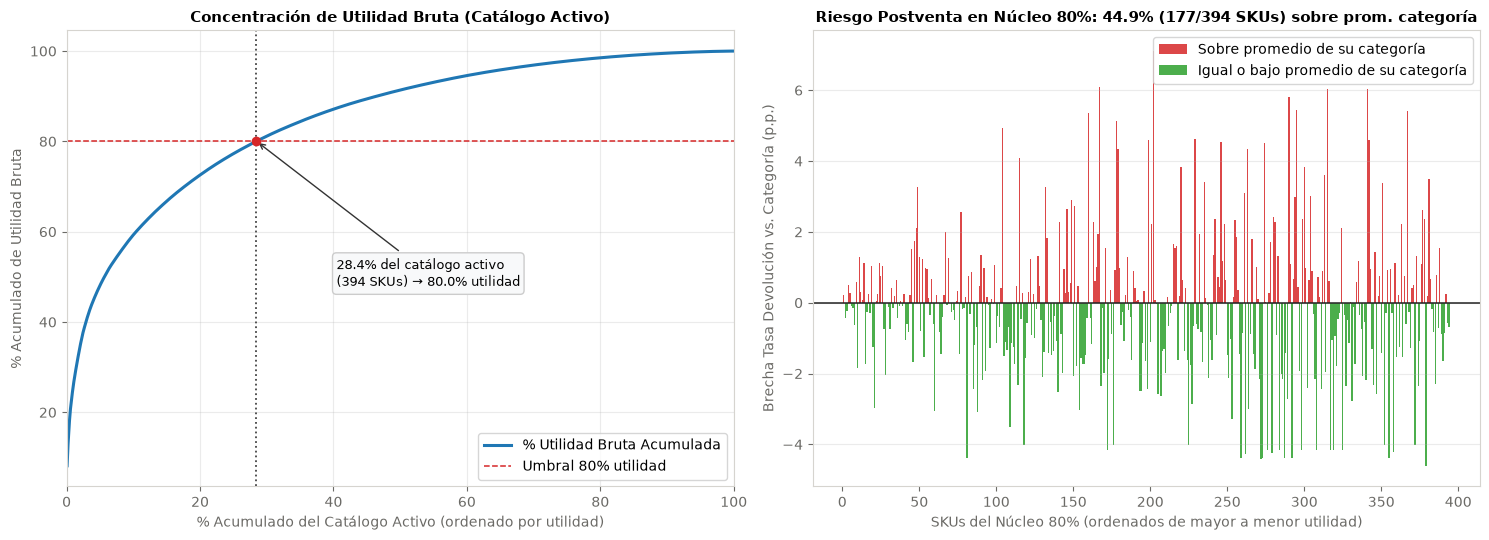

In [247]:
def graficar_eje2(sku_df: pd.DataFrame, top80_df: pd.DataFrame, resumen: dict) -> None:
    """Genera el gráfico de doble panel para el Eje 2."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

    # Panel 1: Curva de Pareto de Utilidad Bruta
    ax1.plot(
        sku_df["cum_sku_pct"],
        sku_df["cum_gp_pct"],
        color="#1f77b4",
        linewidth=2.2,
        label="% Utilidad Bruta Acumulada",
    )
    ax1.axhline(80, color="#d62728", linestyle="--", linewidth=1.1, label="Umbral 80% utilidad")
    ax1.axvline(
        resumen["pct_catalogo_top_80"],
        color="#444444",
        linestyle=":",
        linewidth=1.3,
    )
    ax1.scatter(
        [resumen["pct_catalogo_top_80"]],
        [resumen["utilidad_acum_top_80_pct"]],
        color="#d62728",
        zorder=5,
    )
    ax1.annotate(
        f"{resumen['pct_catalogo_top_80']:.1f}% del catálogo activo\n"
        f"({resumen['skus_top_80']} SKUs) → {resumen['utilidad_acum_top_80_pct']:.1f}% utilidad",
        xy=(resumen["pct_catalogo_top_80"], resumen["utilidad_acum_top_80_pct"]),
        xytext=(min(resumen["pct_catalogo_top_80"] + 12, 58), 48),
        arrowprops=dict(arrowstyle="->", color="#333333"),
        fontsize=9.5,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="#f8f9fa", edgecolor="#cccccc"),
    )
    ax1.set_title("Concentración de Utilidad Bruta (Catálogo Activo)", fontsize=11, fontweight="bold")
    ax1.set_xlabel("% Acumulado del Catálogo Activo (ordenado por utilidad)")
    ax1.set_ylabel("% Acumulado de Utilidad Bruta")
    ax1.set_xlim(0, 100)
    ax1.grid(alpha=0.25)
    ax1.legend(loc="lower right", frameon=True)

    # Panel 2: Brecha de tasa de devolución vs. promedio de categoría en el Núcleo 80%
    x_pos = np.arange(1, len(top80_df) + 1)
    colores = np.where(top80_df["sobre_promedio_cat"], "#d62728", "#2ca02c")

    ax2.bar(x_pos, top80_df["brecha_dev_pp"], color=colores, width=0.85, alpha=0.85)
    ax2.axhline(0, color="#222222", linewidth=1.1)

    ax2.set_title(
        f"Riesgo Postventa en Núcleo 80%: {resumen['fraccion_riesgo_top_80_pct']:.1f}% "
        f"({resumen['skus_riesgo_en_top_80']}/{resumen['skus_top_80']} SKUs) sobre prom. categoría",
        fontsize=11,
        fontweight="bold",
    )
    ax2.set_xlabel("SKUs del Núcleo 80% (ordenados de mayor a menor utilidad)")
    ax2.set_ylabel("Brecha Tasa Devolución vs. Categoría (p.p.)")
    ax2.grid(axis="y", alpha=0.25)

    # Leyenda manual para rojo vs verde
    from matplotlib.patches import Patch
    leyenda_riesgo = [
        Patch(facecolor="#d62728", alpha=0.85, label="Sobre promedio de su categoría"),
        Patch(facecolor="#2ca02c", alpha=0.85, label="Igual o bajo promedio de su categoría"),
    ]
    ax2.legend(handles=leyenda_riesgo, loc="upper right", frameon=True)

    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "Concentración de Utilidad Bruta (Catálogo Activo) y Riesgo Postventa en Núcleo 80%.png",
            dpi=300,
            bbox_inches="tight")
    plt.show()


# --- Ejecución ---
sku_eje2, top80_eje2, resumen_eje2 = calcular_metricas_eje2(TABLAS)
print("Resumen Eje 2:", resumen_eje2)
graficar_eje2(sku_eje2, top80_eje2, resumen_eje2)

### Gráfico 3 — Concentración de Utilidad Bruta (Catálogo Activo)

A través de una curva de Pareto acumulada sobre el catálogo activo (excluyendo órdenes canceladas), se observa cómo se distribuye la utilidad bruta neta ordenada de mayor a menor aporte por SKU. Tras la limpieza de datos, el umbral del **80.0 %** de la utilidad se alcanza con **394 SKUs**, lo que representa el **28.4 %** del catálogo activo. Esto confirma que la mayor parte del margen bruto del negocio sigue concentrada en un subconjunto acotado de productos.

### Gráfico 4 — Riesgo Postventa en Núcleo 80 %

Tomando como base los **394 SKUs** que conforman el núcleo del 80 % de utilidad, este gráfico compara la tasa de devolución de cada producto frente al promedio de su propia categoría (medida en puntos porcentuales, ordenando los SKUs de mayor a menor utilidad). Tras la depuración, **177 de los 394 SKUs** (**44.9 %**) se ubican por encima del promedio de su categoría (en rojo), mientras que el resto se mantiene igual o por debajo (en verde). A continuación, se profundiza en estos **394 SKUs** del núcleo rentable para revisar qué categorías tienen mayor presencia y qué productos acumulan más devoluciones.

Vamos a continuar con el analisis de los 384 prodcutos que representan la Utilidad mas significativa de la Empresa, Analizando por categoria cuales son las que mas se repiten. Asi conmo los productos ordenados con mas devoluciones, para tener el analisis del grafico anterior mas expandido


In [248]:



def afinar_nucleo_80(
    top80_df: pd.DataFrame,
    sku_df: pd.DataFrame,
    top_n_prod: int = 15,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """
    1) Cuenta qué categorías se repiten más dentro del núcleo del 80% de utilidad.
    2) Lista los productos del núcleo 80% con mayor cantidad de devoluciones (líneas devueltas),
       mostrando también tasa de devolución, brecha vs. categoría y reembolsos.
    3) Lista los productos del núcleo 80% con mayor tasa de devolución (para detectar casos de
       poco volumen pero alta tasa).
    """
    # 1. Frecuencia y peso de categorías dentro del Top 80%
    cat_frec_top80 = (
        top80_df.groupby("category", as_index=False)
        .agg(
            skus_en_top80=("product_id", "nunique"),
            lineas_devueltas_top80=("lineas_devueltas", "sum"),
            reembolsos_top80=("reembolsos", "sum"),
            utilidad_top80=("gross_profit", "sum"),
        )
        .sort_values(["skus_en_top80", "lineas_devueltas_top80"], ascending=False)
        .reset_index(drop=True)
    )
    cat_frec_top80["pct_skus_del_top80"] = (
        cat_frec_top80["skus_en_top80"] / len(top80_df) * 100
    ).round(2)

    cat_lider = cat_frec_top80.iloc[0]
    print(
        f"Categoría con más presencia en el umbral (Top 80%): "
        f"{cat_lider['category']} ({int(cat_lider['skus_en_top80'])} SKUs, "
        f"{cat_lider['pct_skus_del_top80']}% del núcleo)"
    )

    # 2. Productos del Top 80% con MÁS devoluciones (conteo absoluto de líneas devueltas)
    mas_devueltos_abs = (
        top80_df.sort_values(
            ["lineas_devueltas", "reembolsos", "brecha_dev_pp"],
            ascending=[False, False, False],
        )
        .assign(
            tasa_sku_pct=lambda d: (d["return_rate"] * 100).round(2),
            tasa_cat_pct=lambda d: (d["cat_avg_return_rate"] * 100).round(2),
            brecha_dev_pp=lambda d: d["brecha_dev_pp"].round(2),
            gross_profit=lambda d: d["gross_profit"].round(2),
            reembolsos=lambda d: d["reembolsos"].round(2),
        )[
            [
                "product_id",
                "sku",
                "product_name",
                "category",
                "lineas_vendidas",
                "lineas_devueltas",
                "tasa_sku_pct",
                "tasa_cat_pct",
                "brecha_dev_pp",
                "reembolsos",
                "gross_profit",
            ]
        ]
        .head(top_n_prod)
        .reset_index(drop=True)
    )

    # 3. Productos del Top 80% con MAYOR tasa de devolución
    mas_devueltos_tasa = (
        top80_df.sort_values(["return_rate", "lineas_devueltas"], ascending=[False, False])
        .assign(
            tasa_sku_pct=lambda d: (d["return_rate"] * 100).round(2),
            tasa_cat_pct=lambda d: (d["cat_avg_return_rate"] * 100).round(2),
            brecha_dev_pp=lambda d: d["brecha_dev_pp"].round(2),
            reembolsos=lambda d: d["reembolsos"].round(2),
            gross_profit=lambda d: d["gross_profit"].round(2),
        )[
            [
                "product_id",
                "sku",
                "product_name",
                "category",
                "lineas_vendidas",
                "lineas_devueltas",
                "tasa_sku_pct",
                "tasa_cat_pct",
                "brecha_dev_pp",
                "reembolsos",
                "gross_profit",
            ]
        ]
        .head(top_n_prod)
        .reset_index(drop=True)
    )

    return cat_frec_top80, mas_devueltos_abs, mas_devueltos_tasa


cat_top80, top_dev_abs, top_dev_tasa = afinar_nucleo_80(top80_eje2, sku_eje2, top_n_prod=15)
display(cat_top80)
print("\n--- Top productos del Núcleo 80% por CANTIDAD de devoluciones ---")
display(top_dev_abs)
print("\n--- Top productos del Núcleo 80% por TASA de devolución ---")
display(top_dev_tasa)

Categoría con más presencia en el umbral (Top 80%): Tents (95 SKUs, 24.11% del núcleo)


,category,skus_en_top80,lineas_devueltas_top80,reembolsos_top80,utilidad_top80,pct_skus_del_top80
0,Tents,95,436,197994.33,2.733896e+06,24.11
1,Sleeping Bags,63,403,136658.51,2.017685e+06,15.99
2,Navigation,63,345,139770.92,1.949425e+06,15.99
3,Footwear,37,414,86374.12,1.076206e+06,9.39
4,Apparel,36,466,60211.80,8.626119e+05,9.14
5,Backpacks,31,1060,193861.81,2.729235e+06,7.87
6,Climbing,30,403,85991.97,1.150616e+06,7.61
7,Cooking,16,549,35887.16,4.771198e+05,4.06
8,Accessories,12,478,37381.76,4.813436e+05,3.05
9,Lighting,11,113,9917.04,1.460354e+05,2.79



--- Top productos del Núcleo 80% por CANTIDAD de devoluciones ---


,product_id,sku,product_name,category,lineas_vendidas,lineas_devueltas,tasa_sku_pct,tasa_cat_pct,brecha_dev_pp,reembolsos,gross_profit
0,518,OUT-00518,Tundra Hydration Pack (Moss),Backpacks,10665,480,4.50,4.27,0.23,87607.12,1390842.46
1,490,OUT-00490,Glacier 45L Backpack (Graphite),Backpacks,6155,236,3.83,4.27,-0.44,21476.37,426709.78
2,722,OUT-00722,Summit Trail Runner (Sand),Footwear,4412,177,4.01,4.24,-0.23,45518.05,396503.03
3,1154,OUT-01154,Summit Camp Stove (Ember),Cooking,3530,151,4.28,4.19,0.09,10628.08,140529.13
4,324,OUT-00324,Summit Merino Base Layer (Moss),Apparel,3069,124,4.04,4.20,-0.16,14647.98,234554.40
5,694,OUT-00694,Tundra 45L Backpack (Ember),Backpacks,2573,117,4.55,4.27,0.28,29262.76,303282.97
6,529,OUT-00529,Canyon Dry Bag (Graphite),Accessories,2052,104,5.07,4.20,0.86,2872.81,32455.68
7,167,OUT-00167,Trail Trekking Poles (Ember),Accessories,2224,99,4.45,4.20,0.25,12397.52,113221.93
8,1167,OUT-01167,Alpine Climbing Harness (Sand),Climbing,1833,79,4.31,4.40,-0.09,16047.64,270274.07
9,193,OUT-00193,Solstice Water Bottle (Sand),Accessories,1649,79,4.79,4.20,0.59,10385.08,162408.53



--- Top productos del Núcleo 80% por TASA de devolución ---


,product_id,sku,product_name,category,lineas_vendidas,lineas_devueltas,tasa_sku_pct,tasa_cat_pct,brecha_dev_pp,reembolsos,gross_profit
0,554,OUT-00554,Trail 2-Person Tent (Ember),Tents,36,4,11.11,4.01,7.10,4233.06,16471.15
1,970,OUT-00970,Glacier Compass (Sand),Navigation,48,5,10.42,4.39,6.03,1689.59,10608.52
2,96,OUT-00096,Nomad Down Sleeping Bag (Graphite),Sleeping Bags,39,4,10.26,4.16,6.09,2546.21,18705.31
3,1196,OUT-01196,Summit Handheld GPS (Ember),Navigation,49,5,10.20,4.39,5.82,2287.19,12435.42
4,1103,OUT-01103,Canyon Down Sleeping Bag (Sand),Sleeping Bags,49,5,10.20,4.16,6.04,3081.47,11416.86
5,579,OUT-00579,Alpine 45L Backpack (Ember),Backpacks,62,6,9.68,4.27,5.41,2062.62,9878.15
6,661,OUT-00661,Summit 3-Season Sleeping Bag (Moss),Sleeping Bags,52,5,9.62,4.16,5.45,1875.73,12222.81
7,82,OUT-00082,Canyon Compass (Ember),Navigation,63,6,9.52,4.39,5.14,4531.10,18210.64
8,811,OUT-00811,Trail Family Dome Tent (Ember),Tents,32,3,9.38,4.01,5.37,2734.74,19121.79
9,1138,OUT-01138,Solstice 2-Person Tent (Cobalt),Tents,112,10,8.93,4.01,4.92,4339.14,26035.06


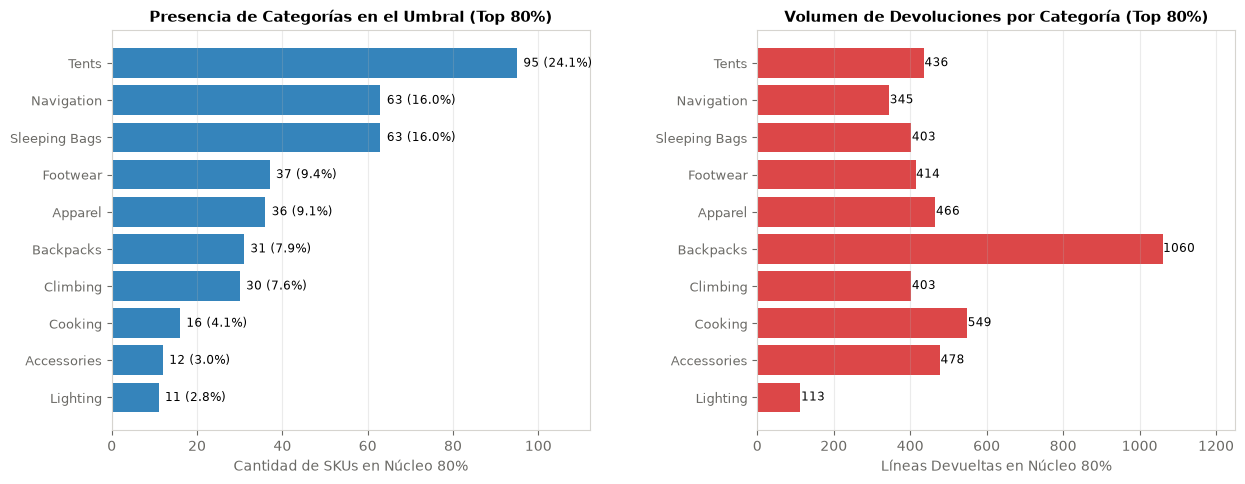

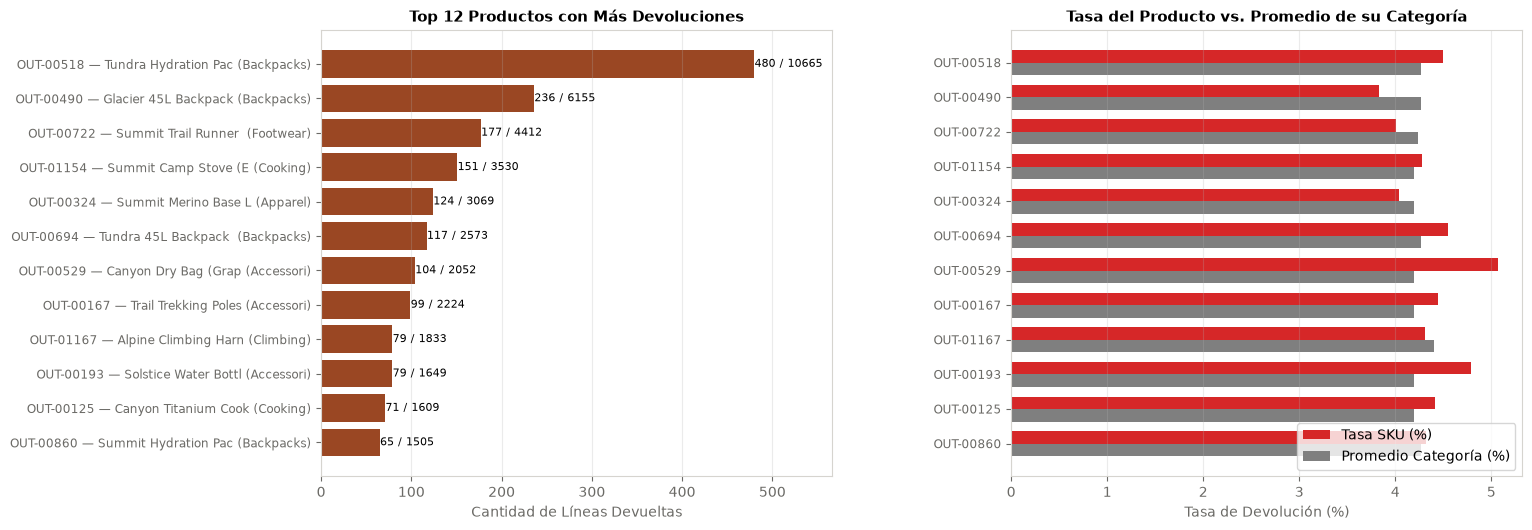

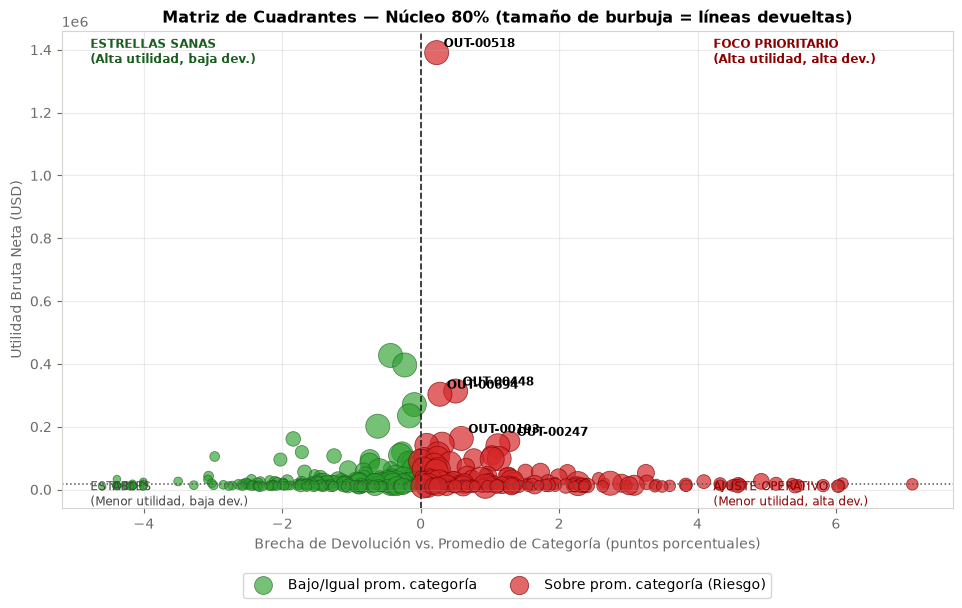

In [249]:

def graficar_cierre_eje2(
    cat_top80: pd.DataFrame,
    top_dev_abs: pd.DataFrame,
    top80_df: pd.DataFrame,
    top_n_prod: int = 12,
) -> None:
    """
    Genera los 3 gráficos finales del Eje 2 a partir de los resultados afinados:
    1) Frecuencia de categorías dentro del Núcleo 80% y volumen de devoluciones.
    2) Ranking de los productos del Núcleo 80% con mayor número de devoluciones,
       comparando su tasa (%) vs. el promedio de su categoría.
    3) Matriz de cuadrantes (Utilidad Bruta vs. Brecha de Devolución en p.p.)
       sobre todo el Núcleo 80%.
    """
    # =========================================================================
    # GRÁFICO 1: Categorías dentro del Núcleo 80% (SKUs y Devoluciones)
    # =========================================================================
    df_cat = cat_top80.sort_values("skus_en_top80", ascending=True).copy()
    y_cat = np.arange(len(df_cat))

    fig1, (ax1a, ax1b) = plt.subplots(1, 2, figsize=(14.5, 5.2))
    fig1.subplots_adjust(wspace=0.35)

    # Panel A: Cantidad de SKUs en el umbral del 80%
    ax1a.barh(y_cat, df_cat["skus_en_top80"], color="#1f77b4", alpha=0.9)
    ax1a.set_yticks(y_cat)
    ax1a.set_yticklabels(df_cat["category"], fontsize=9.5)
    ax1a.set_xlabel("Cantidad de SKUs en Núcleo 80%")
    ax1a.set_title("Presencia de Categorías en el Umbral (Top 80%)", fontsize=11, fontweight="bold")
    ax1a.grid(axis="x", alpha=0.25)
    ax1a.set_xlim(0, df_cat["skus_en_top80"].max() * 1.18)

    for i, (_, r) in enumerate(df_cat.iterrows()):
        ax1a.text(
            r["skus_en_top80"] + 1.5,
            i,
            f"{int(r['skus_en_top80'])} ({r['pct_skus_del_top80']:.1f}%)",
            va="center",
            fontsize=8.5,
        )

    # Panel B: Líneas devueltas acumuladas por categoría dentro del Top 80%
    ax1b.barh(y_cat, df_cat["lineas_devueltas_top80"], color="#d62728", alpha=0.85)
    ax1b.set_yticks(y_cat)
    ax1b.set_yticklabels(df_cat["category"], fontsize=9.5)
    ax1b.set_xlabel("Líneas Devueltas en Núcleo 80%")
    ax1b.set_title("Volumen de Devoluciones por Categoría (Top 80%)", fontsize=11, fontweight="bold")
    ax1b.grid(axis="x", alpha=0.25)
    ax1b.set_xlim(0, df_cat["lineas_devueltas_top80"].max() * 1.18)

    for i, val in enumerate(df_cat["lineas_devueltas_top80"]):
        ax1b.text(val + 1.5, i, f"{int(val)}", va="center", fontsize=8.5)

    plt.savefig(RESULTS_DIR / "Volumen de Devoluciones por Categoría (Top 80%).png",
    dpi=300,
    bbox_inches="tight")

    plt.show()

    # =========================================================================
    # GRÁFICO 2: Top Productos con Más Devoluciones (Conteo y Tasa vs Categoría)
    # =========================================================================
    sub_prod = top_dev_abs.head(top_n_prod).iloc[::-1].reset_index(drop=True)
    y_prod = np.arange(len(sub_prod))
    etiquetas_prod = [
        f"{r['sku']} — {r['product_name'][:20]} ({r['category'][:9]})"
        for _, r in sub_prod.iterrows()
    ]

    fig2, (ax2a, ax2b) = plt.subplots(1, 2, figsize=(15.5, 5.8))
    fig2.subplots_adjust(wspace=0.35)

    # Panel A: Líneas devueltas absolutas
    ax2a.barh(y_prod, sub_prod["lineas_devueltas"], color="#8c2d04", alpha=0.88)
    ax2a.set_yticks(y_prod)
    ax2a.set_yticklabels(etiquetas_prod, fontsize=8.5)
    ax2a.set_xlabel("Cantidad de Líneas Devueltas")
    ax2a.set_title(f"Top {len(sub_prod)} Productos con Más Devoluciones", fontsize=11, fontweight="bold")
    ax2a.grid(axis="x", alpha=0.25)
    ax2a.set_xlim(0, sub_prod["lineas_devueltas"].max() * 1.18)

    for i, (_, r) in enumerate(sub_prod.iterrows()):
        ax2a.text(
            r["lineas_devueltas"] + 0.3,
            i,
            f"{int(r['lineas_devueltas'])} / {int(r['lineas_vendidas'])}",
            va="center",
            fontsize=8,
        )

    # Panel B: Comparación de tasa del SKU vs promedio de su categoría
    h = 0.36
    ax2b.barh(y_prod + h / 2, sub_prod["tasa_sku_pct"], height=h, color="#d62728", label="Tasa SKU (%)")
    ax2b.barh(y_prod - h / 2, sub_prod["tasa_cat_pct"], height=h, color="#7f7f7f", label="Promedio Categoría (%)")
    ax2b.set_yticks(y_prod)
    ax2b.set_yticklabels([r["sku"] for _, r in sub_prod.iterrows()], fontsize=8.5)
    ax2b.set_xlabel("Tasa de Devolución (%)")
    ax2b.set_title("Tasa del Producto vs. Promedio de su Categoría", fontsize=11, fontweight="bold")
    ax2b.grid(axis="x", alpha=0.25)
    ax2b.legend(loc="lower right")
        
    plt.savefig(RESULTS_DIR / "Tasa del Producto vs. Promedio de su Categoría.png",
    dpi=300,
    bbox_inches="tight")

    plt.show()

    # =========================================================================
    # GRÁFICO 3: Matriz de Cuadrantes (Utilidad Bruta vs. Brecha de Devolución)
    # =========================================================================
    df_q = top80_df.copy()
    med_gp = df_q["gross_profit"].median()

    fig3, ax3 = plt.subplots(figsize=(11.5, 6.2))

    # Colorear según si supera o no el promedio de su categoría
    sanos = df_q[~df_q["sobre_promedio_cat"]]
    riesgo = df_q[df_q["sobre_promedio_cat"]]

    ax3.scatter(
        sanos["brecha_dev_pp"],
        sanos["gross_profit"],
        s=np.clip(sanos["lineas_devueltas"] * 10 + 30, 30, 300),
        color="#2ca02c",
        alpha=0.65,
        edgecolors="#1b5e20",
        linewidth=0.6,
        label="Bajo/Igual prom. categoría",
    )
    ax3.scatter(
        riesgo["brecha_dev_pp"],
        riesgo["gross_profit"],
        s=np.clip(riesgo["lineas_devueltas"] * 10 + 30, 30, 300),
        color="#d62728",
        alpha=0.70,
        edgecolors="#7f0000",
        linewidth=0.6,
        label="Sobre prom. categoría (Riesgo)",
    )

    # Líneas divisoras de cuadrantes
    ax3.axvline(0, color="#222222", linestyle="--", linewidth=1.2)
    ax3.axhline(med_gp, color="#555555", linestyle=":", linewidth=1.1)

    # Etiquetas de cuadrantes
    x_min, x_max = ax3.get_xlim()
    y_min, y_max = ax3.get_ylim()
    ax3.text(x_min + (0 - x_min) * 0.08, y_max * 0.93, "ESTRELLAS SANAS\n(Alta utilidad, baja dev.)", fontsize=8.5, color="#1b5e20", fontweight="bold")
    ax3.text(x_max * 0.55, y_max * 0.93, "FOCO PRIORITARIO\n(Alta utilidad, alta dev.)", fontsize=8.5, color="#8b0000", fontweight="bold")
    ax3.text(x_min + (0 - x_min) * 0.08, y_min + (med_gp - y_min) * 0.12, "ESTABLES\n(Menor utilidad, baja dev.)", fontsize=8.5, color="#444444")
    ax3.text(x_max * 0.55, y_min + (med_gp - y_min) * 0.12, "AJUSTE OPERATIVO\n(Menor utilidad, alta dev.)", fontsize=8.5, color="#8b0000")

    # Anotar los 5 productos más críticos en utilidad dentro de riesgo
    top_criticos = riesgo.sort_values("gross_profit", ascending=False).head(5)
    for _, r in top_criticos.iterrows():
        ax3.annotate(
            f"{r['sku']}",
            xy=(r["brecha_dev_pp"], r["gross_profit"]),
            xytext=(5, 4),
            textcoords="offset points",
            fontsize=8.5,
            fontweight="bold",
        )

    ax3.set_xlabel("Brecha de Devolución vs. Promedio de Categoría (puntos porcentuales)")
    ax3.set_ylabel("Utilidad Bruta Neta (USD)")
    ax3.set_title(
        "Matriz de Cuadrantes — Núcleo 80% (tamaño de burbuja = líneas devueltas)",
        fontsize=11.5,
        fontweight="bold",
    )
    ax3.grid(alpha=0.25)
    ax3.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
    plt.savefig(RESULTS_DIR / "Matriz de Cuadrantes — Núcleo 80%.png",
            dpi=300,
            bbox_inches="tight")

    plt.show()

graficar_cierre_eje2(cat_top80, top_dev_abs, top80_eje2, top_n_prod=12)

##  Gráfico 5 — Categorías en el Umbral: amplitud de utilidad frente a carga de devoluciones

Este gráfico contrasta cuántos SKUs del núcleo rentable aporta cada categoría con el volumen total de líneas devueltas que acumulan dentro de ese mismo grupo. Revela una asimetría estructural entre generar margen y absorber fricción postventa:

* **Soporte de rentabilidad:** **Tents** lidera la presencia en el umbral con **95 SKUs** (**24.1 %** del núcleo), seguida por **Navigation** (**63 SKUs**, **16.0 %**) y **Sleeping Bags** (**63 SKUs**, **16.0 %**), conformando la base más amplia de productos rentables.
* **Concentración desproporcionada de devoluciones:** **Backpacks** acumula **1,060 líneas devueltas** con **31 SKUs** (**7.9 %** del umbral), mientras que **Cooking** (**549** líneas en **16 SKUs**, **4.1 %**) y **Accessories** (**478** líneas en **12 SKUs**, **3.0 %**) muestran un peso operativo elevado frente a su baja cantidad de SKUs rentables.
* **Implicación analítica:** la amplitud de SKUs rentables no garantiza bajo desgaste operativo; en categorías como `Backpacks`, `Cooking` y `Accessories`, la presión de devoluciones exige revisar factores de uso, ajuste, compatibilidad o expectativas del cliente.

---

## Gráfico 6 — Top 12 Productos con Más Devoluciones y Tasa vs. Categoría: volumen bruto frente a comportamiento relativo

Este gráfico doble separa el conteo absoluto de líneas devueltas (junto con el volumen vendido) de la comparación porcentual entre la tasa del producto y el promedio de su categoría. Permite distinguir entre devoluciones impulsadas por alta rotación y casos donde el producto se comporta peor que su propio rubro:

* **Liderazgo por escala y aporte financiero:** **Tundra Hydration Pack (Moss) (OUT-00518)** (`Backpacks`) encabeza el volumen con **480 líneas devueltas** sobre **10,665 vendidas** (~4.50 % de tasa), ubicándose por encima del promedio de su categoría (~4.3 %) y consolidándose como el punto de mayor impacto integral.
* **Alto volumen por rotación:** referencias como **Glacier 45L Backpack (Graphite) (OUT-00490)** (**236 / 6,155**, ~3.83 %) y **Summit Trail Runner (Sand) (OUT-00722)** (**177 / 4,412**, ~4.01 %) registran cifras elevadas de devolución asociadas a su alto volumen de salida, pero con tasas por debajo del promedio de su respectiva categoría (~4.3 %).
* **Desempeño por encima del estándar de categoría:** productos como **Canyon Dry Bag (Graphite) (OUT-00529)** (**104 / 2,052**, ~5.07 %), **Solstice Water Bottle (Sand) (OUT-00193)** (**79 / 1,649**, ~4.79 %) y **Tundra 45L Backpack (Ember) (OUT-00694)** (**117 / 2,573**, ~4.55 %) muestran tasas superiores a la media de su categoría, señalando candidatos prioritarios para revisar ficha técnica, calidad o idoneidad de uso.

---

## Gráfico 7 — Matriz de Cuadrantes del Núcleo 80 %: síntesis estratégica de utilidad y riesgo

La matriz posiciona cada SKU del umbral según su utilidad bruta neta (eje vertical), su desempeño de devolución frente al promedio de su categoría (eje horizontal, dividido en menor/igual en verde y mayor en rojo) y el tamaño de las líneas devueltas (tamaño de burbuja). Resume dónde concentrar la gestión:

* **Prioridad máxima por peso económico y operativo:** **Tundra Hydration Pack (Moss) (OUT-00518)** sobresale en la zona alta de utilidad (~1.4M USD) con una burbuja prominente y tasa ligeramente superior a la de su categoría, por lo que cualquier mejora en su postventa protege directamente una parte sustancial de la utilidad del catálogo.
* **Productos de utilidad relevante con mayor presión de devolución:** referencias como **Tundra 45L Backpack (Ember) (OUT-00694)**, **Solstice Water Bottle (Sand) (OUT-00193)** y los SKUs destacados en el cuadrante superior derecho (**OUT-00448** y **OUT-00247**) combinan generación de utilidad significativa con tasas por encima de la media de su rubro, ameritando revisión focalizada de producto y experiencia de compra.
* **Casos de menor utilidad con tasas elevadas:** las burbujas ubicadas en la franja inferior derecha reflejan artículos con menor aporte monetario agregado pero mayor carga relativa de devolución frente a su categoría, donde conviene evaluar si el problema es de calidad puntual o de volumen limitado.

---

## 5. Interpretación y conclusiones

<details open>
  <summary><b>Hallazgos y conclusiones. Pregunta 1: Descuentos vs. envío gratuito</b></summary>

**Pregunta:** ¿Cómo interactúan los descuentos promocionales con el umbral de envío gratuito de \$75 USD, y en qué segmentos de órdenes la coincidencia de alto descuento y exención de envío erosiona críticamente el margen?

### Respuesta corta

El margen disminuye por dos vías que se suman: a mayor descuento, menor margen en todos los tramos, y al cruzar el umbral de \$75 la tienda absorbe el costo de envío. El segmento donde coinciden ambas condiciones, **órdenes con subtotal de \$75–90 y descuento de 11–20%**, presenta el menor margen promedio: **31.6%** una vez descontado el envío estimado y **28.7%** al restar también los reembolsos, frente a 48.1% en órdenes menores a \$60 sin descuento.

### Principales hallazgos

1. **El descuento reduce el margen de forma consistente.** En los cuatro tramos de subtotal, las órdenes con descuento de 11–20% tienen entre 8.6 y 13.4 puntos menos de margen que las órdenes sin descuento del mismo tramo.

2. **El envío gratuito genera un quiebre en el umbral de \$75.** Al incorporar el costo de envío, el tramo de \$75–90 queda por debajo del de \$60–74.99 en los tres niveles de descuento (41.8% vs. 46.4%, 37.4% vs. 43.5% y 31.6% vs. 35.1%). Es decir, las órdenes que apenas superan el umbral muestran que pueden ser menos rentables que las que se quedan justo debajo.

3. **El costo de envío pesa más en tickets pequeños.** En el segmento de \$75–90 con descuento alto, el envío absorbido equivale a 9.2% del subtotal, porque la compra promedio es de solo \$81. En el tramo mayor a \$90 ese mismo costo se diluye, y el margen se recupera parcialmente (35.9%).

4. **El margen bruto se ve influenciado por el costo del envío.** Con la fórmula de margen bruto, que no considera el envío, el tramo de \$75–90 aparece como el más rentable (51.0% sin descuento). Solo al incorporar el envío se revela como el más vulnerable. Medir rentabilidad sin el subsidio logístico lleva a una conclusión opuesta.

5. **El umbral se evalúa antes del descuento.** Por eso, 305 clientes recibieron envío gratis aunque, después del descuento, pagaron menos de \$75. La tienda otorga ambos beneficios a compras que no alcanzarían el umbral con el monto realmente cobrado.

6. **Las devoluciones no cambian el patrón.** Restar los reembolsos reduce el margen entre 2.4 y 5.4 puntos en todas las celdas, sin concentrarse en un segmento en particular. El segmento de \$75–90 con descuento alto sigue siendo el de menor margen. Esto se explica porque las devoluciones son poco frecuentes: en ninguna celda más del 6.3% de las órdenes tuvo reembolso.

### Supuestos del análisis

- **Costo de envío:** la base no registra lo que la paquetería le cobra a la tienda. Se asumió que cada orden con envío gratis le cuesta \$7.48, el promedio de la tarifa que pagan los clientes de órdenes menores a \$75. Es el mismo valor para todas las órdenes, sin considerar peso, destino ni transportista.
- **Devoluciones:** solo se restaron los reembolsos aprobados o pagados. Se asumió que el monto reembolsado se pierde completo, sin considerar que el producto pueda regresar al inventario y revenderse.
- **Universo de órdenes:** se excluyeron las órdenes canceladas y en proceso (no generaron ingreso) y las órdenes mayoristas (705 órdenes por encima del percentil 99.5).
- **Base del margen:** el margen se calcula sobre la venta neta (subtotal menos descuento). No incluye impuestos, que no son ingreso de la tienda.
- **Promedios:** cada celda muestra el promedio del margen por orden, por lo que todas las órdenes pesan igual, sin importar su monto.

### Lo que los datos permiten concluir

- Que **a mayor descuento, menor margen**, en todos los tramos. Esta conclusión no depende del supuesto de envío.
- Que **el envío gratuito reduce el margen de las órdenes que apenas superan el umbral**, y que su peso relativo disminuye conforme aumenta el monto de la compra.
- Que **existen órdenes que reciben envío gratis pagando menos de \$75**, debido a que el umbral se evalúa antes del descuento.
- Que **ningún segmento opera con pérdida en promedio**: incluso el peor conserva cerca de 29% de margen, porque los costos de los productos y el descuento máximo (20%) no alcanzan a superar el precio de venta. La erosión es relativa, no una pérdida absoluta.

### Lo que no puede afirmarse con la información disponible

- **Que el segmento de \$75–90 con descuento alto sea siempre el peor.** Esta conclusión depende del costo de envío supuesto. Sin el costo real de paquetería, solo puede afirmarse que el segmento es de los más afectados.
- **Causalidad.** El análisis es descriptivo: muestra que el descuento y el envío gratis coinciden con márgenes menores, pero no prueba que los causen. Además, los datos son sintéticos y fueron generados con reglas de negocio fijas, por lo que los patrones reflejan esas reglas y no necesariamente el comportamiento de clientes reales.
- **Si los incentivos son rentables en conjunto.** No sabemos cuántas ventas se habrían perdido sin descuento o sin envío gratis. Un margen menor por orden puede compensarse con un mayor volumen de ventas, y la base no permite medir ese efecto.
- **La rentabilidad final de la tienda.** El margen calculado solo considera costo de producto, descuento, envío estimado y reembolsos. Quedan fuera otros costos como almacén, marketing, comisiones de marketplace o el costo logístico de procesar las devoluciones.
- **Conclusiones firmes en celdas pequeñas.** Algunas combinaciones tienen entre 111 y 254 órdenes, frente a casi 60,000 en la celda más grande. Sus promedios son menos estables y diferencias de 1–2 puntos entre ellas no deben interpretarse como relevantes.
-------------------------------------------------------------------------------






<details open>
<summary><b>Hallazgos y conclusiones. Eje 2: Concentración de utilidad y riesgo de catálogo</b></summary>

<br>

**Pregunta:** ¿Qué proporción del catálogo activo concentra el 80 % de la utilidad bruta, qué categoría domina el núcleo rentable, y qué fracción o productos críticos presentan mayor riesgo por devoluciones?

### Respuesta corta

El 80.0 % de la utilidad bruta neta se concentra en **394 SKUs** (**28.4 %** del catálogo activo), y **177 de esos 394 SKUs** (**44.9 %**) presentan tasas de devolución por encima del promedio de su categoría. La amplitud de la utilidad se apoya en **Tents** (95 SKUs, 24.1 % del núcleo), mientras que el mayor volumen de devoluciones del umbral recae en **Backpacks** (1,060 líneas) y el impacto integral más crítico en **Tundra Hydration Pack (Moss) (OUT-00518)** (~1.4M USD de utilidad y 480 líneas devueltas).

### Principales hallazgos

1. **La utilidad está altamente concentrada en una fracción del catálogo.** El 28.4 % del catálogo activo (394 SKUs) acumula el 80.0 % de la utilidad bruta neta, apoyándose en el `subtotal` con prorrateo de descuentos y reembolsos, y excluyendo impuestos y envíos para aislar el margen comercial del producto.
2. **Tents lidera la amplitud del núcleo rentable.** Dentro del umbral del 80 %, **Tents** es la categoría más repetida con **95 SKUs** (24.1 % del núcleo), seguida por **Navigation** (63 SKUs, 16.0 %) y **Sleeping Bags** (63 SKUs, 16.0 %), las cuales sostienen el grueso de la rentabilidad con una carga de devoluciones moderada frente a su tamaño.
3. **Backpacks concentra la mayor presión de devoluciones en el umbral.** Con **31 SKUs** (7.9 % del núcleo), **Backpacks** acumula **1,060 líneas devueltas**; junto con **Cooking** (549 líneas en 16 SKUs, 4.1 %) y **Accessories** (478 líneas en 12 SKUs, 3.0 %), evidencia una fricción postventa elevada en relación con su presencia en el Top 80 %.
4. **Tundra Hydration Pack (Moss) (OUT-00518) es el activo más crítico por escala e impacto financiero.** Lidera la utilidad bruta neta (~1.4M USD) y el conteo absoluto de devoluciones con **480 líneas devueltas** sobre 10,665 vendidas (~4.50 %), ubicándose por encima del promedio de su categoría (~4.3 %).
5. **Volumen de devoluciones no siempre equivale a exceso de tasa.** Productos con alto volumen de ventas como **Glacier 45L Backpack (Graphite) (OUT-00490)** (236 devoluciones sobre 6,155 vendidas, ~3.83 %) y **Summit Trail Runner (Sand) (OUT-00722)** (177 devoluciones sobre 4,412 vendidas, ~4.01 %) suman muchas líneas devueltas por escala comercial, pero se mantienen por debajo del promedio de su categoría; en contraste, **Canyon Dry Bag (Graphite) (OUT-00529)** (104 / 2,052, ~5.07 %), **Solstice Water Bottle (Sand) (OUT-00193)** (79 / 1,649, ~4.79 %) y **Tundra 45L Backpack (Ember) (OUT-00694)** (117 / 2,573, ~4.55 %) combinan volumen relevante con tasas superiores a su rubro.
6. **El cuadrante de riesgo sintetiza prioridades operativas.** **Tundra Hydration Pack (Moss) (OUT-00518)** destaca en la franja superior de utilidad con alto volumen de devolución, **Tundra 45L Backpack (Ember) (OUT-00694)**, **Solstice Water Bottle (Sand) (OUT-00193)** y referencias como **OUT-00448** y **OUT-00247** muestran utilidad relevante con brecha positiva frente a su categoría, y las burbujas en la zona inferior derecha reflejan productos de menor utilidad agregada con mayor presión relativa de devolución.

</details>